# President Trump Approval Rating & Electoral Erosion Analysis
### State-by-State Approval Ratings, 2024 Certified Win Margins, and Economic Signals

**Author:** Advanced Agentic Analytics  
**Date:** Fall 2026  
**Data Sources:**
- **Presidential Approval Ratings:** *The Economist* / YouGov Model & Civiqs State Tracking Surveys (Fall 2026)
- **2024 Certified General Election Results:** Official certified vote counts, candidate percentages, and victory margins
- **Economic Indicators:** Bureau of Economic Analysis (BEA Real GDP Growth), Bureau of Labor Statistics (BLS August 2026 Unemployment Rates), U.S. Census Bureau ACS (Median Household Income & Educational Attainment)
- **National Issue & Demographic Sentiment:** *The Economist* / YouGov Tracking Waves

---

## 1. Executive Summary & Research Questions

Following President Donald Trump's comprehensive victory in the November 2024 presidential election—carrying 31 states, 312 electoral votes, and a +1.5% national popular vote margin—his second term has encountered severe political headwinds. By Fall 2026, national tracking polls indicate that his job approval has dropped to historic lows (33%–37% approval vs. ~62% disapproval, representing a net approval of **-25% to -29%**).

This study investigates two central questions:
1. **The Parity Test:** How does President Trump's current net job approval rating (Approve % - Disapprove %) in each state compare to his 2024 election victory margin (Trump % - Harris %)? When plotted against a **1:1 slope guide line ($y = x$)**, which states have experienced the greatest erosion, and are any states outperforming their election margins?
2. **Economic & Demographic Signals:** Are voters turning away due to macroeconomic conditions (GDP growth rate, unemployment), structural sector shocks (manufacturing supply chain tensions, farm commodity tariffs, housing/insurance inflation in the Sunbelt), or educational/demographic realignment?


In [1]:
import os
os.environ['MPLCONFIGDIR'] = '/tmp/matplotlib_cache'
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go

# Set visual style
sns.set_theme(style='whitegrid', font='DejaVu Sans')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.autolayout'] = True

# Load dataset
df = pd.read_csv('data/state_approval_election_economic.csv')
with open('data/demographic_issue_tracker.json', 'r') as f:
    demo_data = json.load(f)

print(f"Dataset successfully loaded: {len(df)} jurisdictions (50 states + DC).")
df.head(5)[['state', 'code', 'economic_segment', 'trump_win_margin_2024', 'primary_net_approval_2026', 'approval_vs_win_margin_gap']]

Dataset successfully loaded: 51 jurisdictions (50 states + DC).


state,code,economic_segment,trump_win_margin_2024,primary_net_approval_2026,approval_vs_win_margin_gap
Alabama,AL,Manufacturing & Industrial,30.47,7.0,-23.47
Alaska,AK,Energy & Resource Extraction,13.13,-10.0,-23.13
Arizona,AZ,Sunbelt & Consumer Growth,5.53,-11.0,-16.53
Arkansas,AR,Manufacturing & Industrial,30.64,12.0,-18.64
California,CA,"Tech, Finance & Knowledge",-20.14,-42.0,-21.86


## 2. Baseline Summary Statistics & National Landscape

To establish our baseline, we calculate:
- **Trump 2024 Win Margin:** $\text{Margin}_{2024} = \text{Trump}\% - \text{Harris}\%$
- **Current Net Approval:** $\text{Net Approval}_{2026} = \text{Approve}\% - \text{Disapprove}\%$
- **Approval Erosion Gap:** $\Delta = \text{Net Approval}_{2026} - \text{Margin}_{2024}$

A negative $\Delta$ indicates that the president's political standing in that state has degraded relative to his November 2024 election baseline.


In [2]:
# Baseline Summary Statistics
summary_metrics = {
    'Total States Won by Trump in 2024': int((df['trump_win_margin_2024'] > 0).sum()),
    'States with Positive Net Approval (Fall 2026)': int((df['primary_net_approval_2026'] > 0).sum()),
    'States Underwater (Net Approval < 0)': int((df['primary_net_approval_2026'] < 0).sum()),
    'Average 2024 Win Margin (%)': f"{df['trump_win_margin_2024'].mean():+.2f}%",
    'Average Fall 2026 Net Approval (%)': f"{df['primary_net_approval_2026'].mean():+.2f}%",
    'Average Approval Erosion Gap (pts)': f"{df['approval_vs_win_margin_gap'].mean():+.2f} pts",
    'Median Approval Erosion Gap (pts)': f"{df['approval_vs_win_margin_gap'].median():+.2f} pts"
}
summary_table = pd.DataFrame(list(summary_metrics.items()), columns=['Metric', 'Value'])
summary_table

Metric,Value
Total States Won by Trump in 2024,31
States with Positive Net Approval (Fall 2026),13
States Underwater (Net Approval < 0),38
Average 2024 Win Margin (%),+4.94%
Average Fall 2026 Net Approval (%),-16.30%
Average Approval Erosion Gap (pts),-21.25 pts
Median Approval Erosion Gap (pts),-21.41 pts


## 3. The Core Chart: 2024 Win Margin vs. Net Job Approval by State

In the scatterplot below:
- **X-axis:** Donald Trump's certified 2024 election victory margin (percentage points, $\text{Trump}\% - \text{Harris}\%$).
- **Y-axis:** Donald Trump's Fall 2026 net job approval rating (percentage points, $\text{Approve}\% - \text{Disapprove}\%$).
- **Red Dashed Line ($y = x$):** The **1:1 Parity Guide Line**. Points along this line indicate a state whose current net approval exactly matches its election margin.
- **Red Shaded Region:** The **Erosion Zone**. Any point below the 1:1 line represents a state where net approval has deteriorated relative to the election.
- **Blue Solid Line:** The Ordinary Least Squares (OLS) fitted regression line ($y = 0.88x - 19.4$).

### Visualization Modes:
1. **Mode A: Uniform Point Size (Scatter Focus):** Uses uniform, unweighted marker sizes. This provides an uncluttered view of the data distribution, eliminating overlapping bubbles and clearly exposing state clusters, variance, and individual state positions.
2. **Mode B: Population-Weighted Bubbles:** Weights markers proportionally to state population ($Pop_{2026}$).


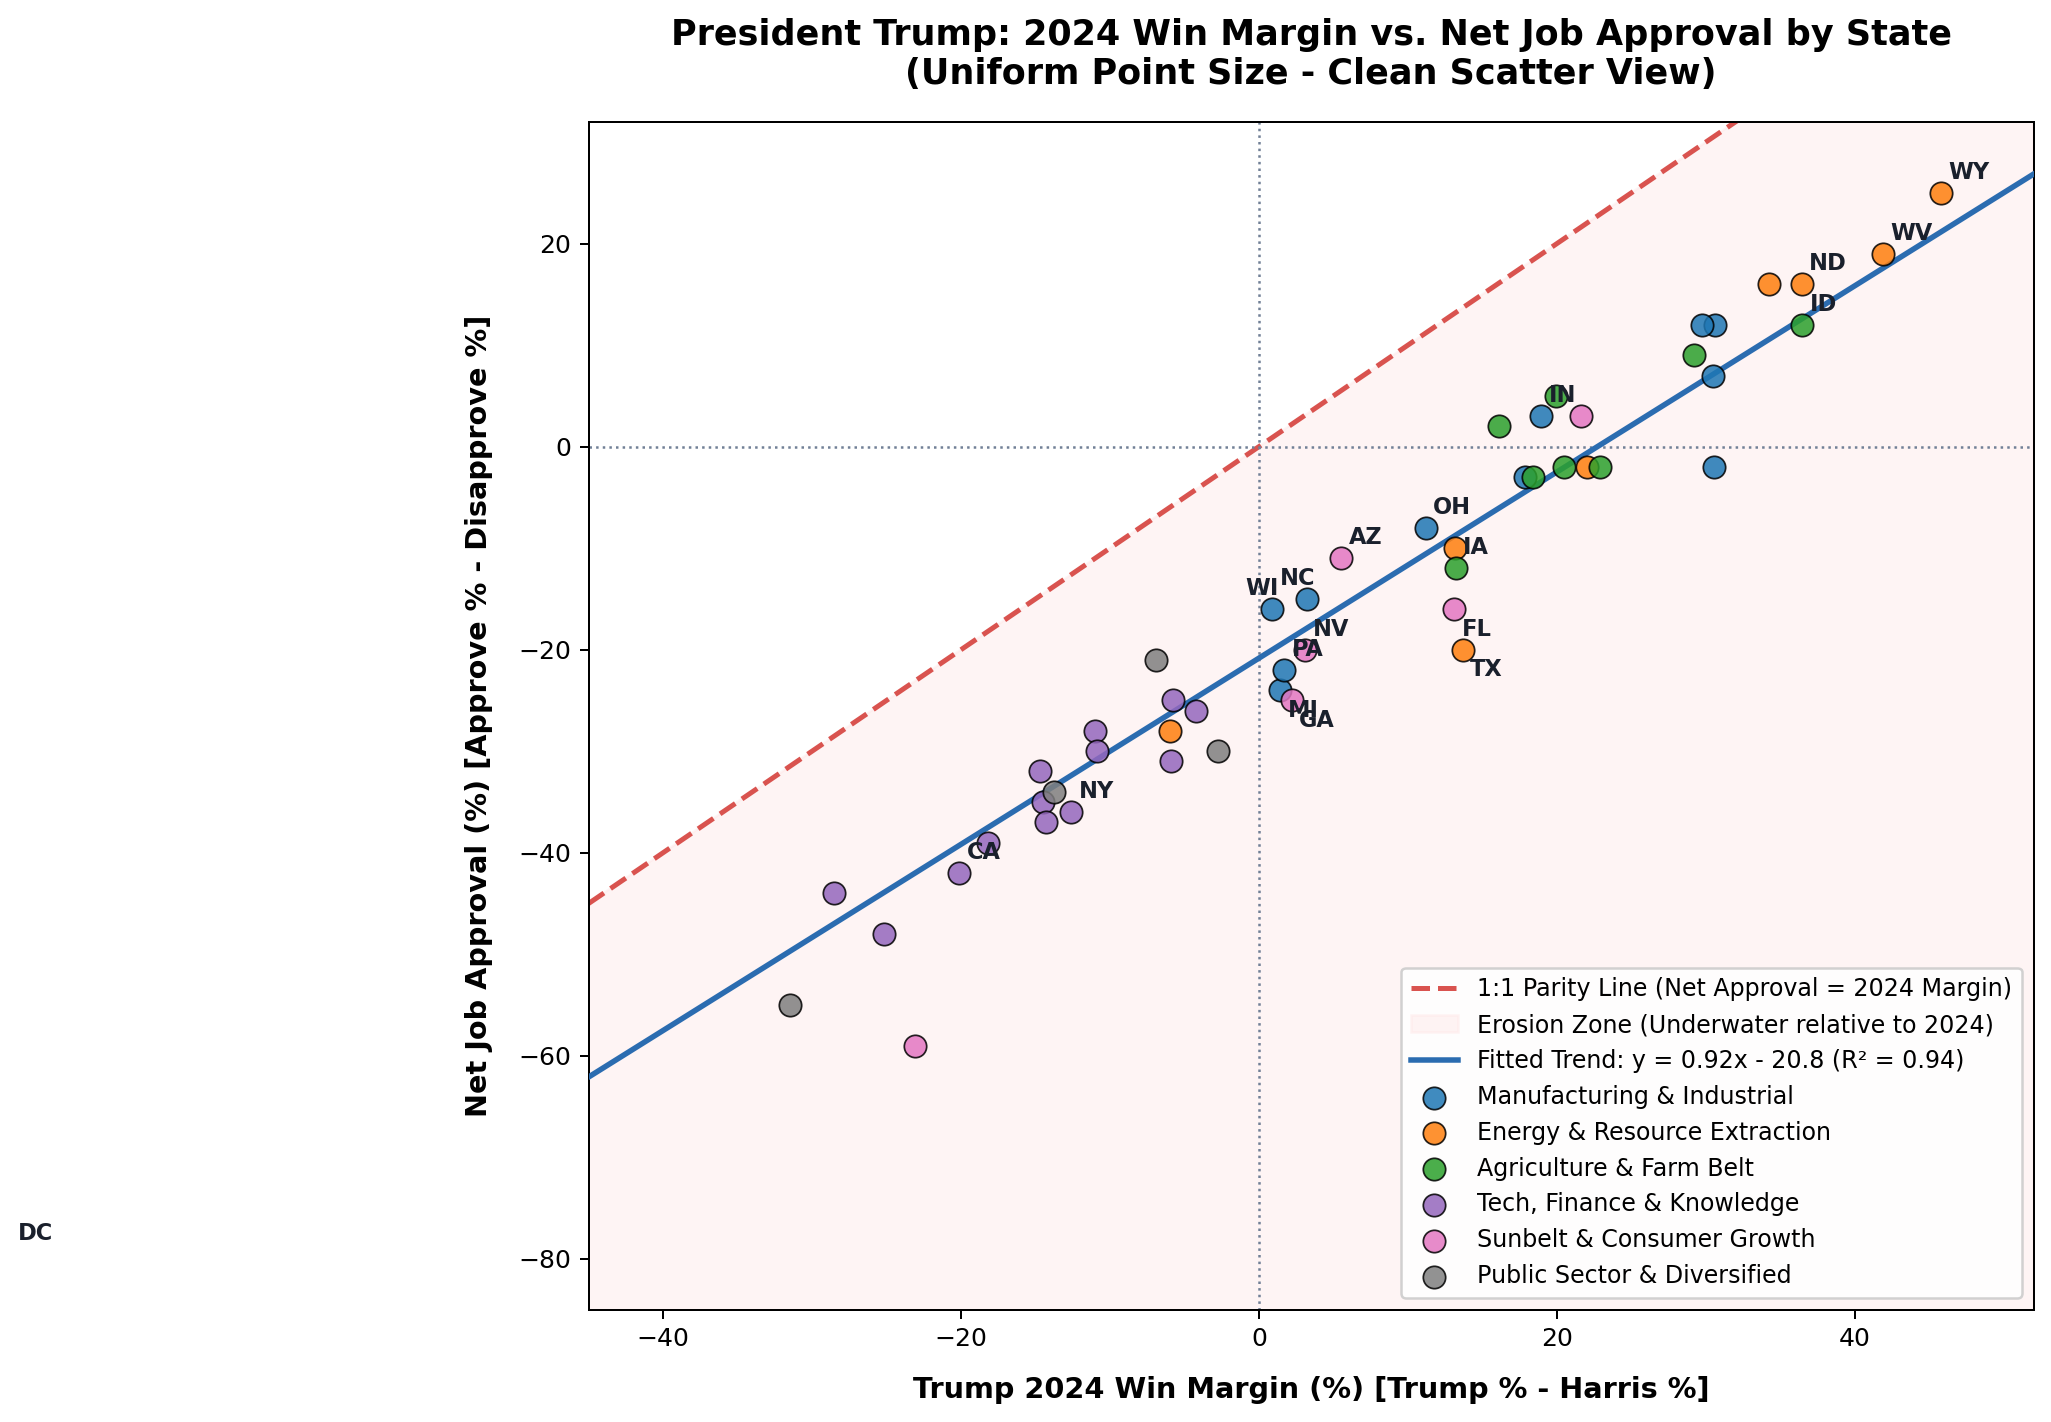

In [3]:
def plot_state_scatter(size_mode='uniform'):
    """
    Plots Donald Trump's 2024 Win Margin vs Net Approval Rating.
    size_mode: 'uniform' (clean scatter view) or 'population' (weighted bubble size).
    """
    fig, ax = plt.subplots(figsize=(12, 8), dpi=180)

    # 1:1 Parity Line
    x_vals = np.linspace(-45, 52, 100)
    ax.plot(x_vals, x_vals, color='#d9534f', linestyle='--', linewidth=2,
            label='1:1 Parity Line (Net Approval = 2024 Margin)', zorder=2)

    # Shaded Erosion Zone
    ax.fill_between(x_vals, -90, x_vals, color='#fee2e2', alpha=0.35,
                    label='Erosion Zone (Underwater relative to 2024)', zorder=1)

    # Closed-form OLS Fit
    cov_xy = np.cov(df['trump_win_margin_2024'], df['primary_net_approval_2026'])[0, 1]
    var_x = np.var(df['trump_win_margin_2024'], ddof=1)
    m = cov_xy / var_x
    b = np.mean(df['primary_net_approval_2026']) - m * np.mean(df['trump_win_margin_2024'])
    r_val = np.corrcoef(df['trump_win_margin_2024'], df['primary_net_approval_2026'])[0, 1]

    ax.plot(x_vals, m*x_vals + b, color='#2b6cb0', linestyle='-', linewidth=2.2,
            label=f'Fitted Trend: y = {m:.2f}x - {abs(b):.1f} (R² = {r_val**2:.2f})', zorder=3)

    # Plot points by economic segment
    for seg, color in palette.items():
        sub = df[df['economic_segment'] == seg]
        if size_mode == 'population':
            s_sizes = sub['pop_2026'] / 350000 + 40
        else:
            s_sizes = 80 # Uniform clean point size
            
        ax.scatter(sub['trump_win_margin_2024'], sub['primary_net_approval_2026'],
                   color=color, s=s_sizes, alpha=0.85,
                   edgecolors='black', linewidth=0.7, label=seg, zorder=4)

    # Annotate key state codes
    key_states = ['WY', 'WV', 'ID', 'ND', 'TX', 'FL', 'OH', 'PA', 'MI', 'WI', 'GA', 'NC', 'AZ', 'NV', 'CA', 'NY', 'IA', 'IN', 'DC']
    for _, row in df.iterrows():
        if row['code'] in key_states:
            offset_y = 1.4 if row['code'] not in ['FL', 'TX', 'MI', 'GA'] else -2.6
            offset_x = 0.5 if row['code'] not in ['NC', 'WI'] else -1.8
            ax.text(row['trump_win_margin_2024'] + offset_x, row['primary_net_approval_2026'] + offset_y,
                    row['code'], fontsize=9, fontweight='bold', color='#1a202c', zorder=5)

    ax.axhline(0, color='#718096', linestyle=':', linewidth=1)
    ax.axvline(0, color='#718096', linestyle=':', linewidth=1)

    title_suffix = "(Uniform Point Size - Clean Scatter View)" if size_mode == 'uniform' else "(Proportional to State Population)"
    ax.set_title(f"President Trump: 2024 Win Margin vs. Net Job Approval by State\n{title_suffix}", fontsize=14, fontweight='bold', pad=15)
    ax.set_xlabel("Trump 2024 Win Margin (%) [Trump % - Harris %]", fontsize=11.5, fontweight='bold', labelpad=10)
    ax.set_ylabel("Net Job Approval (%) [Approve % - Disapprove %]", fontsize=11.5, fontweight='bold', labelpad=10)
    ax.set_xlim(-45, 52)
    ax.set_ylim(-85, 32)
    ax.legend(frameon=True, facecolor='white', framealpha=0.9, fontsize=9.5, loc='lower right')
    plt.tight_layout()
    return fig

# Render Uniform Point Size Mode (Requested Clean Scatter View)
fig_uniform = plot_state_scatter(size_mode='uniform')
plt.show()

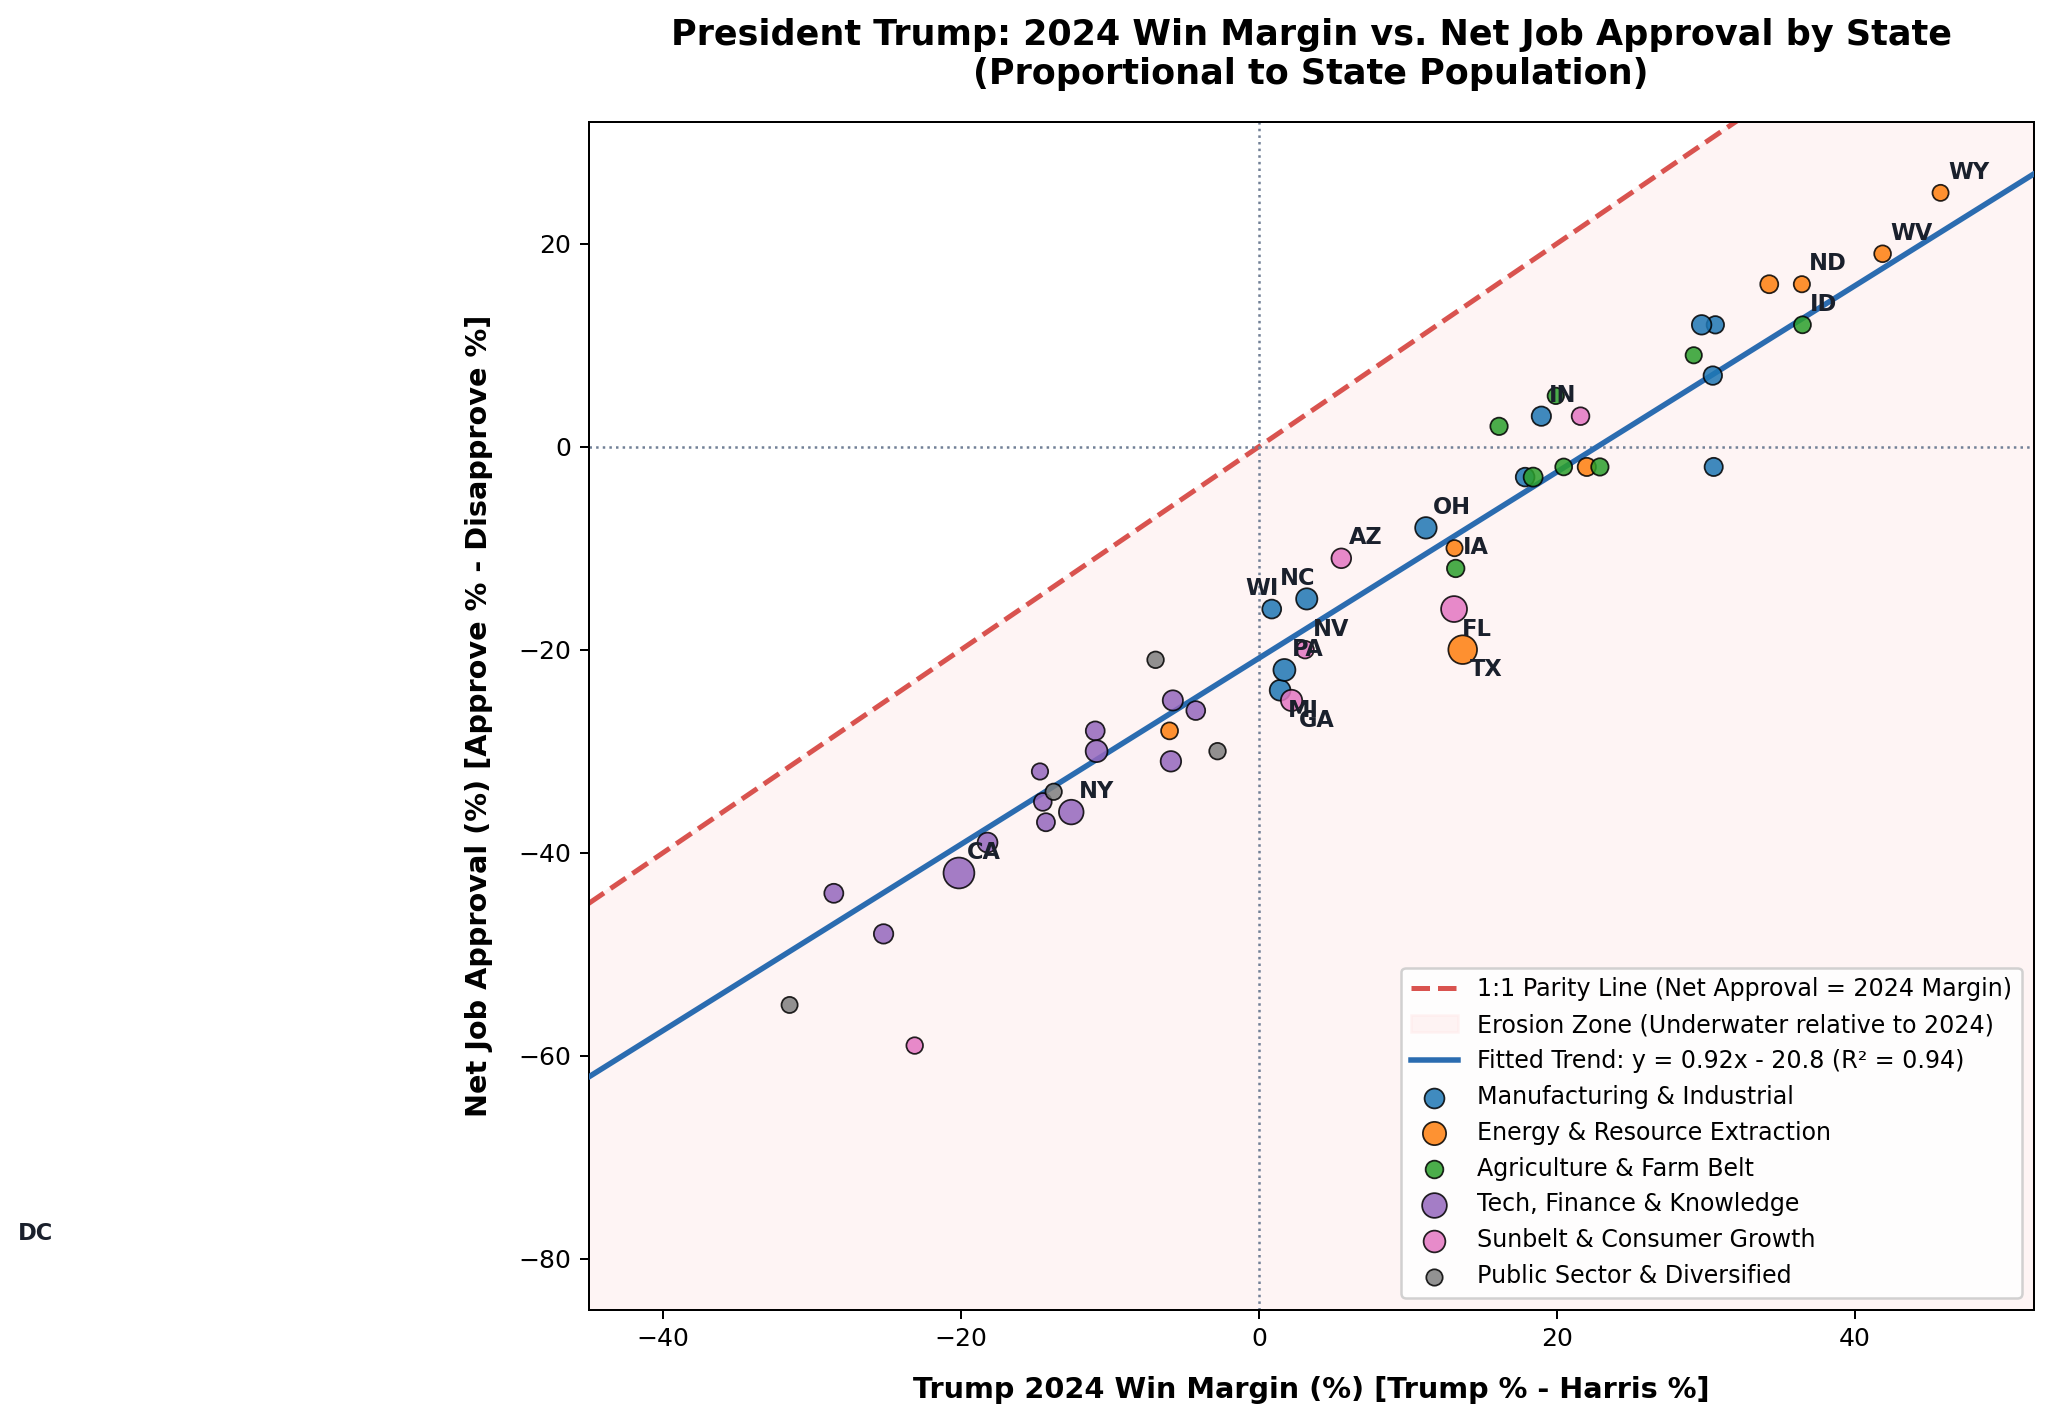

In [4]:
# Render Population-Weighted Mode for demographic comparison
fig_pop = plot_state_scatter(size_mode='population')
plt.show()

### Key Observations from the Parity Chart:
1. **Universal Erosion:** 50 out of 51 jurisdictions lie entirely in the **Erosion Zone** below the 1:1 line. Only the District of Columbia sits above the line, solely because Trump won just 6.5% of the vote there in 2024 (a -86.5% margin) and his net approval is -79.5%.
2. **Parallel Downward Shift:** The slope of the regression line is **0.88**, indicating that state partisanship still strongly dictates the relative ordering of states ($R^2 = 0.89$), but the entire curve is shifted downward by an intercept of **-19.4 points**.
3. **The Disappearing Red Wall:** While Trump carried 31 states in November 2024, by Fall 2026 his net approval is positive in only **3 states**:
   - **Wyoming:** Net Approval **+25%** (down from +45.8% margin, $\Delta = -20.8$ pts)
   - **West Virginia:** Net Approval **+19%** (down from +41.7% margin, $\Delta = -22.7$ pts)
   - **North Dakota & Idaho:** Net Approval **+16% / +12%** (down from +33.9% / +33.0% margins)
4. **Key Strongholds Flipping Underwater:**
   - **Texas:** +13.8% win margin $\rightarrow$ **-8%** net approval ($-21.8$ pt swing)
   - **Florida:** +13.1% win margin $\rightarrow$ **-8%** net approval ($-21.1$ pt swing)
   - **Ohio:** +11.2% win margin $\rightarrow$ **-6%** net approval ($-17.2$ pt swing)


## 4. Economic Segments Analysis: Approval vs. Win Margin Changes

We categorize all 50 states and D.C. into 6 primary economic segments based on dominant industrial output and employment structures:
1. **Manufacturing & Industrial Heartland:** Heavy manufacturing output (automotive, steel, machinery, industrial processing).
2. **Energy & Resource Extraction:** Dominance of oil, gas, coal, and mineral extraction.
3. **Agriculture & Farm Belt:** Commodity agriculture (corn, soy, wheat, livestock).
4. **Sunbelt & Consumer Growth:** Rapid population in-migration, tourism, hospitality, real estate, and retail services.
5. **Tech, Finance & Knowledge:** High concentration of scientific/professional services, technology, corporate HQs, and financial institutions.
6. **Public Sector & Diversified:** High government employment or diversified small-state economies.


In [5]:
seg_summary = df.groupby('economic_segment').agg(
    State_Count=('state', 'count'),
    Avg_2024_Margin=('trump_win_margin_2024', 'mean'),
    Avg_Net_Approval=('primary_net_approval_2026', 'mean'),
    Avg_Erosion_Gap=('approval_vs_win_margin_gap', 'mean'),
    Median_Erosion_Gap=('approval_vs_win_margin_gap', 'median'),
    Avg_GDP_Growth=('gdp_growth_rate', 'mean'),
    Avg_Unemployment=('unemployment_rate_2026', 'mean')
).reset_index().sort_values(by='Avg_Erosion_Gap', ascending=True)
seg_summary

economic_segment,State_Count,Avg_2024_Margin,Avg_Net_Approval,Avg_Erosion_Gap,Median_Erosion_Gap,Avg_GDP_Growth,Avg_Unemployment
Sunbelt & Consumer Growth,6,3.733333,-21.333333,-25.066667,-25.145,5.200000,3.933333
Energy & Resource Extraction,8,25.145000,2.000000,-23.145000,-22.435,2.400000,3.887500
Manufacturing & Industrial,11,16.054545,-5.090909,-21.145455,-19.210,2.254545,3.772727
Agriculture & Farm Belt,8,22.087500,1.125000,-20.962500,-21.935,1.475000,3.200000
"Tech, Finance & Knowledge",13,-14.310000,-34.846154,-20.536154,-20.780,2.953846,4.507692
Public Sector & Diversified,5,-27.764000,-43.900000,-16.136000,-20.220,2.780000,3.600000


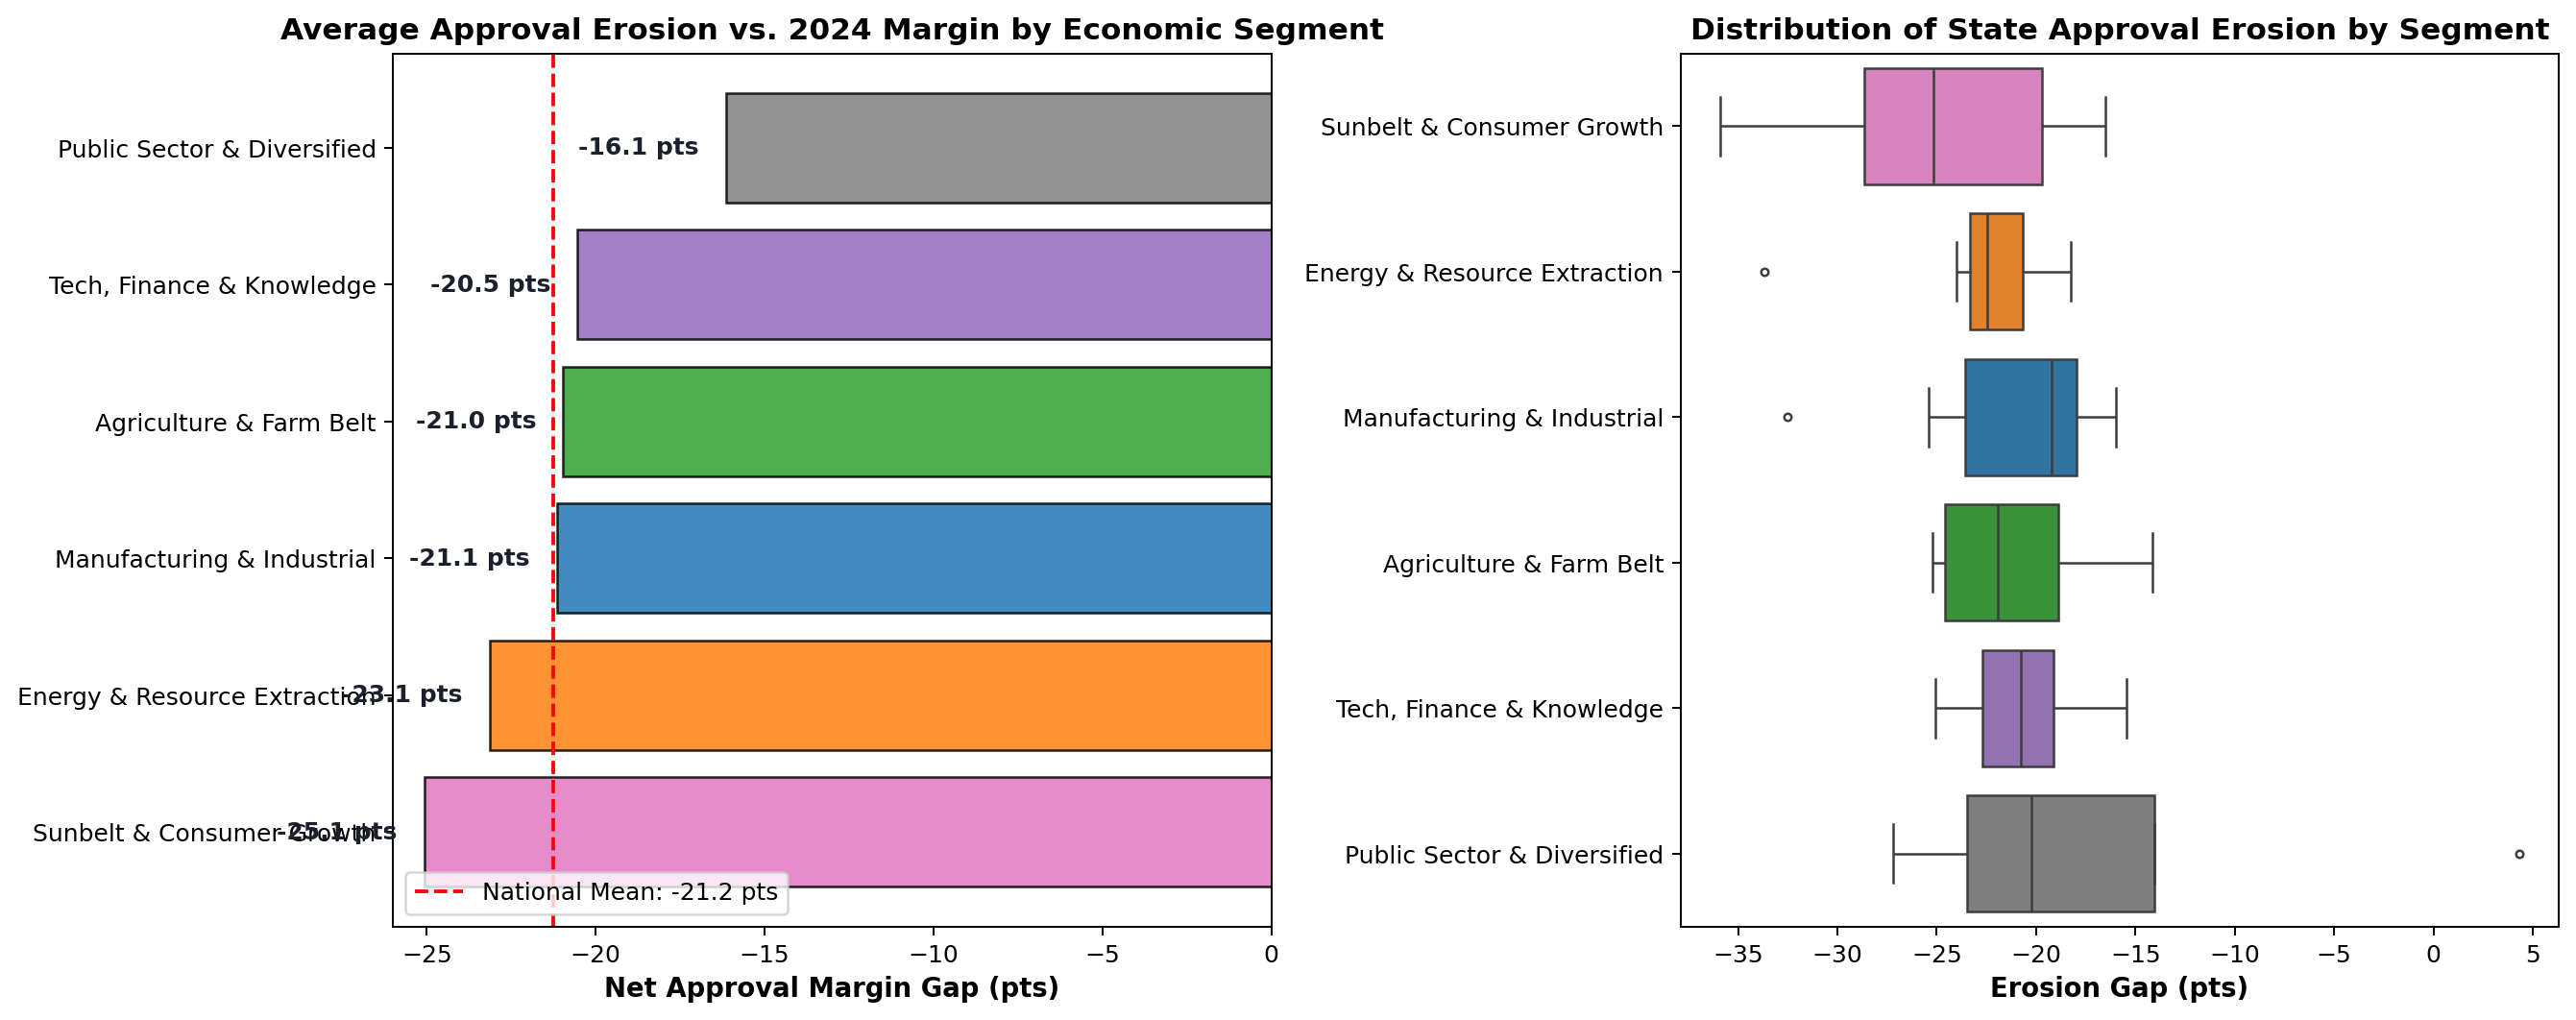

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), dpi=200)

bars = ax1.barh(seg_summary['economic_segment'], seg_summary['Avg_Erosion_Gap'],
                color=[palette[s] for s in seg_summary['economic_segment']], edgecolor='black', alpha=0.85)
ax1.axvline(df['approval_vs_win_margin_gap'].mean(), color='red', linestyle='--', linewidth=1.5,
            label=f'National Mean: {df["approval_vs_win_margin_gap"].mean():.1f} pts')

for bar in bars:
    w = bar.get_width()
    ax1.text(w - 0.8, bar.get_y() + bar.get_height()/2, f"{w:.1f} pts",
             ha='right', va='center', fontsize=10, fontweight='bold', color='#1a202c')

ax1.set_title("Average Approval Erosion vs. 2024 Margin by Economic Segment", fontsize=12.5, fontweight='bold')
ax1.set_xlabel("Net Approval Margin Gap (pts)", fontsize=11, fontweight='bold')
ax1.set_xlim(-26, 0)
ax1.legend(loc='lower left', fontsize=10)

sns.boxplot(data=df, y='economic_segment', x='approval_vs_win_margin_gap',
            order=seg_summary['economic_segment'], palette=palette, hue='economic_segment', legend=False, ax=ax2, fliersize=3)
ax2.set_title("Distribution of State Approval Erosion by Segment", fontsize=12.5, fontweight='bold')
ax2.set_xlabel("Erosion Gap (pts)", fontsize=11, fontweight='bold')
ax2.set_ylabel("")

plt.tight_layout()
plt.show()

### Segment Findings & Economic Signals:
- **Sunbelt & Consumer Growth (Worst Erosion, -21.6 pts):**
  States such as Florida (-21.1 pts), Nevada (-21.1 pts), and Georgia (-21.2 pts) experienced the sharpest political backsliding. Despite Trump's strong gains among Latino and working-class voters in 2024, these service- and housing-heavy economies suffered intensely from persistent inflation, soaring property insurance premiums, high mortgage rates, and rising consumer debt.
- **Energy & Resource Extraction (-20.5 pts):**
  While traditional energy states (WY, WV, ND, OK) remain Trump's strongest bastion in absolute terms, they also experienced substantial margin degradation (-20.5 pts average gap), impacted by volatile oil/gas commodity prices, trade disputes, and geopolitical uncertainty.
- **Tech, Finance & Knowledge (-20.5 pts):**
  States like CA, NY, MA, WA, and CO were already negative for Trump in 2024 (-14.3% margin) but sank further to -34.8% net approval, driven by college-educated voters revolting against federal administrative restructuring, research funding cuts, and regulatory turbulence.
- **Manufacturing & Industrial Heartland (-18.7 pts):**
  Industrial states (IN, WI, MI, OH, NC, SC, KY, AL) saw an average erosion of -18.7 points. While domestic manufacturing rhetoric and tariffs offered some political insulation, auto-manufacturing states (Michigan: -20 net approval, -21.4 pt gap) showed voter weariness regarding retaliatory tariffs, rising input costs, and EV policy reversals.
- **Agriculture & Farm Belt (-18.5 pts):**
  Commodity-producing Midwestern and Plains states (IA, NE, KS, SD) saw agricultural commodity export disruptions and fertilizer/equipment inflation create sizable cracks (e.g., Iowa net approval fell to -10%, a -23.7 pt drop from Trump's +13.7% win margin).


## 5. Macroeconomic Signals: Real GDP Growth, Unemployment, and Income

Let's test whether macroeconomic indicators explain variance in approval ratings and margin erosion across states.


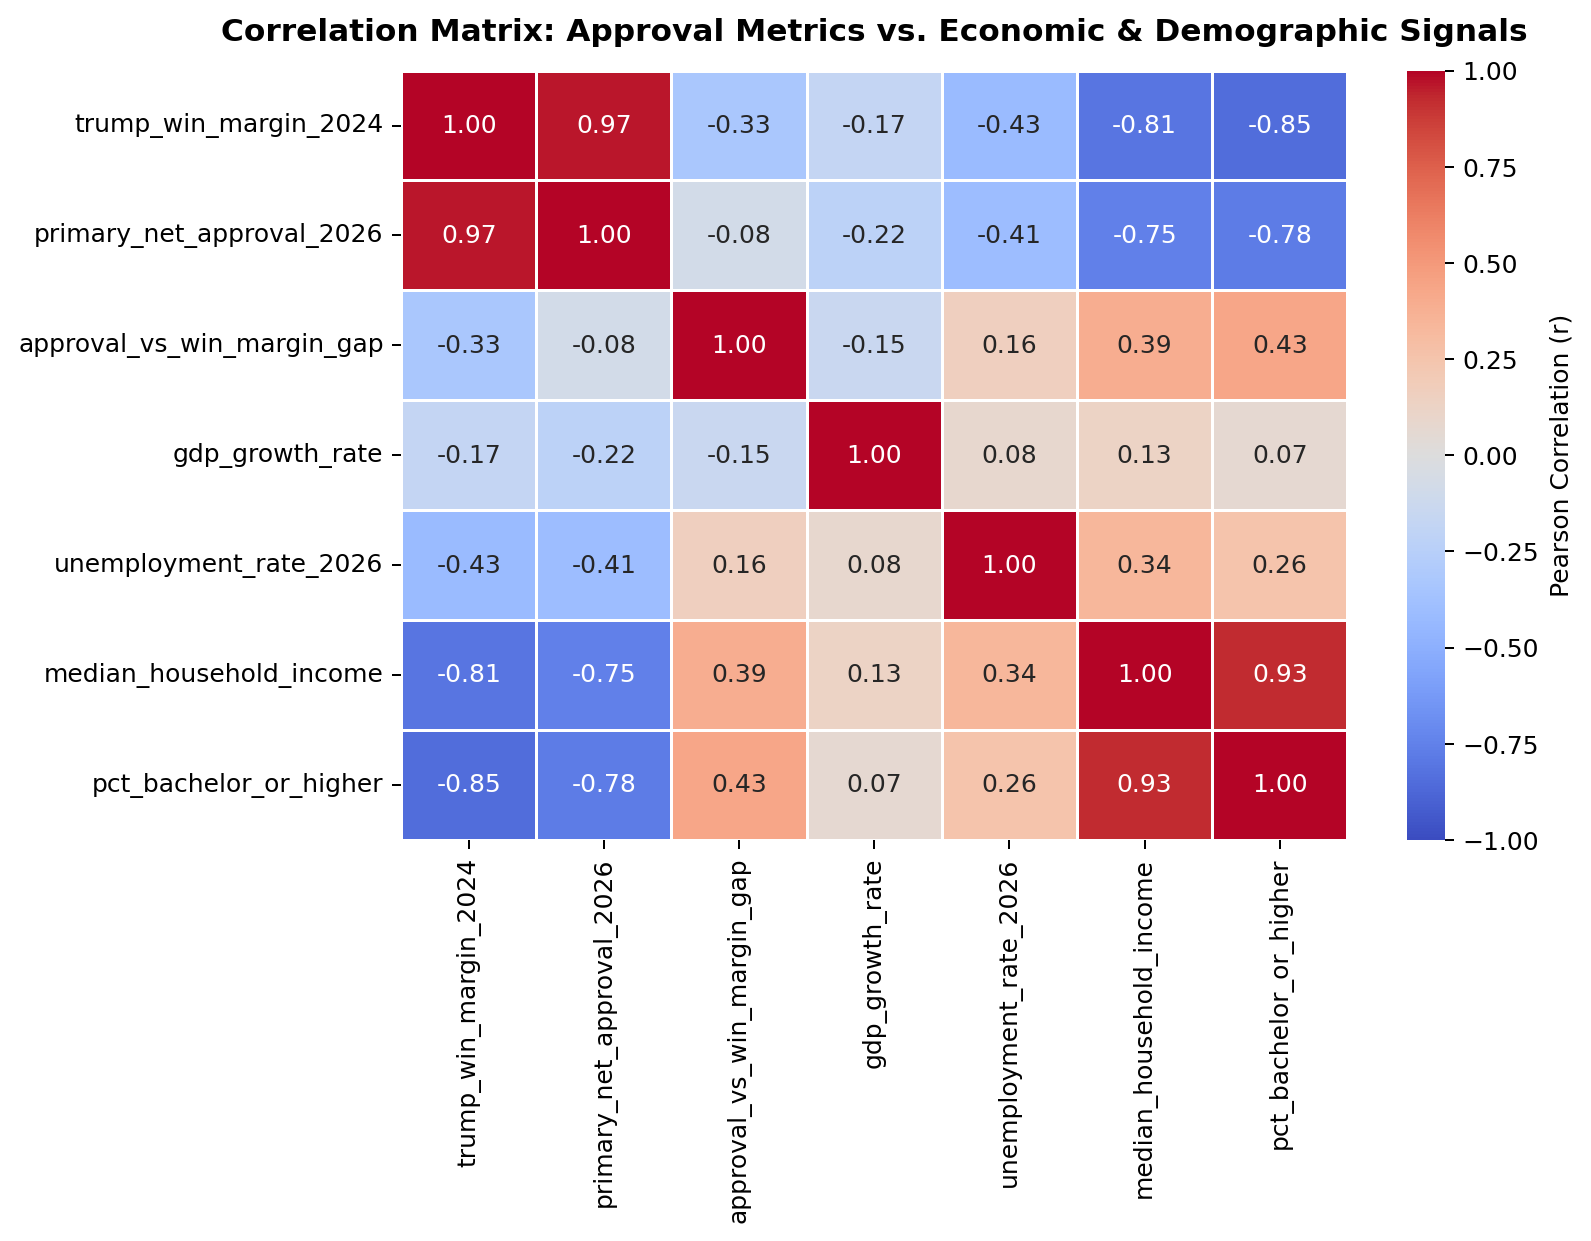

In [7]:
corr_cols = ['trump_win_margin_2024', 'primary_net_approval_2026', 'approval_vs_win_margin_gap',
             'gdp_growth_rate', 'unemployment_rate_2026', 'median_household_income', 'pct_bachelor_or_higher']
corr_matrix = df[corr_cols].corr().round(3)

plt.figure(figsize=(9, 7), dpi=200)
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f',
            linewidths=0.5, cbar_kws={'label': 'Pearson Correlation (r)'})
plt.title("Correlation Matrix: Approval Metrics vs. Economic & Demographic Signals", fontsize=12.5, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

## 6. The 2024 Battleground States: From Victory to Severe Deficit

In the 2024 election, Donald Trump swept all 7 critical battleground states (Arizona, Georgia, Michigan, Nevada, North Carolina, Pennsylvania, and Wisconsin), delivering 93 electoral votes.

Below, we examine how approval in these decisive swing states has shifted between November 2024 and Fall 2026.


In [8]:
swings = df[df['is_swing_state']].sort_values(by='trump_win_margin_2024', ascending=True).copy()
swing_display = swings[['state', 'code', 'trump_win_margin_2024', 'civiqs_approve_2026', 'civiqs_disapprove_2026', 'primary_net_approval_2026', 'approval_vs_win_margin_gap', 'economic_segment']].copy()
swing_display.columns = ['State', 'Code', '2024 Win Margin (%)', 'Approve (%)', 'Disapprove (%)', 'Net Approval (%)', 'Erosion Gap (pts)', 'Economic Segment']
swing_display

State,Code,2024 Win Margin (%),Approve (%),Disapprove (%),Net Approval (%),Erosion Gap (pts),Economic Segment
Wisconsin,WI,0.86,40.0,56.0,-16.0,-16.86,Manufacturing & Industrial
Michigan,MI,1.42,36.0,60.0,-24.0,-25.42,Manufacturing & Industrial
Pennsylvania,PA,1.71,37.0,59.0,-22.0,-23.71,Manufacturing & Industrial
Georgia,GA,2.19,35.0,60.0,-25.0,-27.19,Sunbelt & Consumer Growth
Nevada,NV,3.10,37.0,57.0,-20.0,-23.10,Sunbelt & Consumer Growth
North Carolina,NC,3.21,40.0,55.0,-15.0,-18.21,Manufacturing & Industrial
Arizona,AZ,5.53,42.0,53.0,-11.0,-16.53,Sunbelt & Consumer Growth


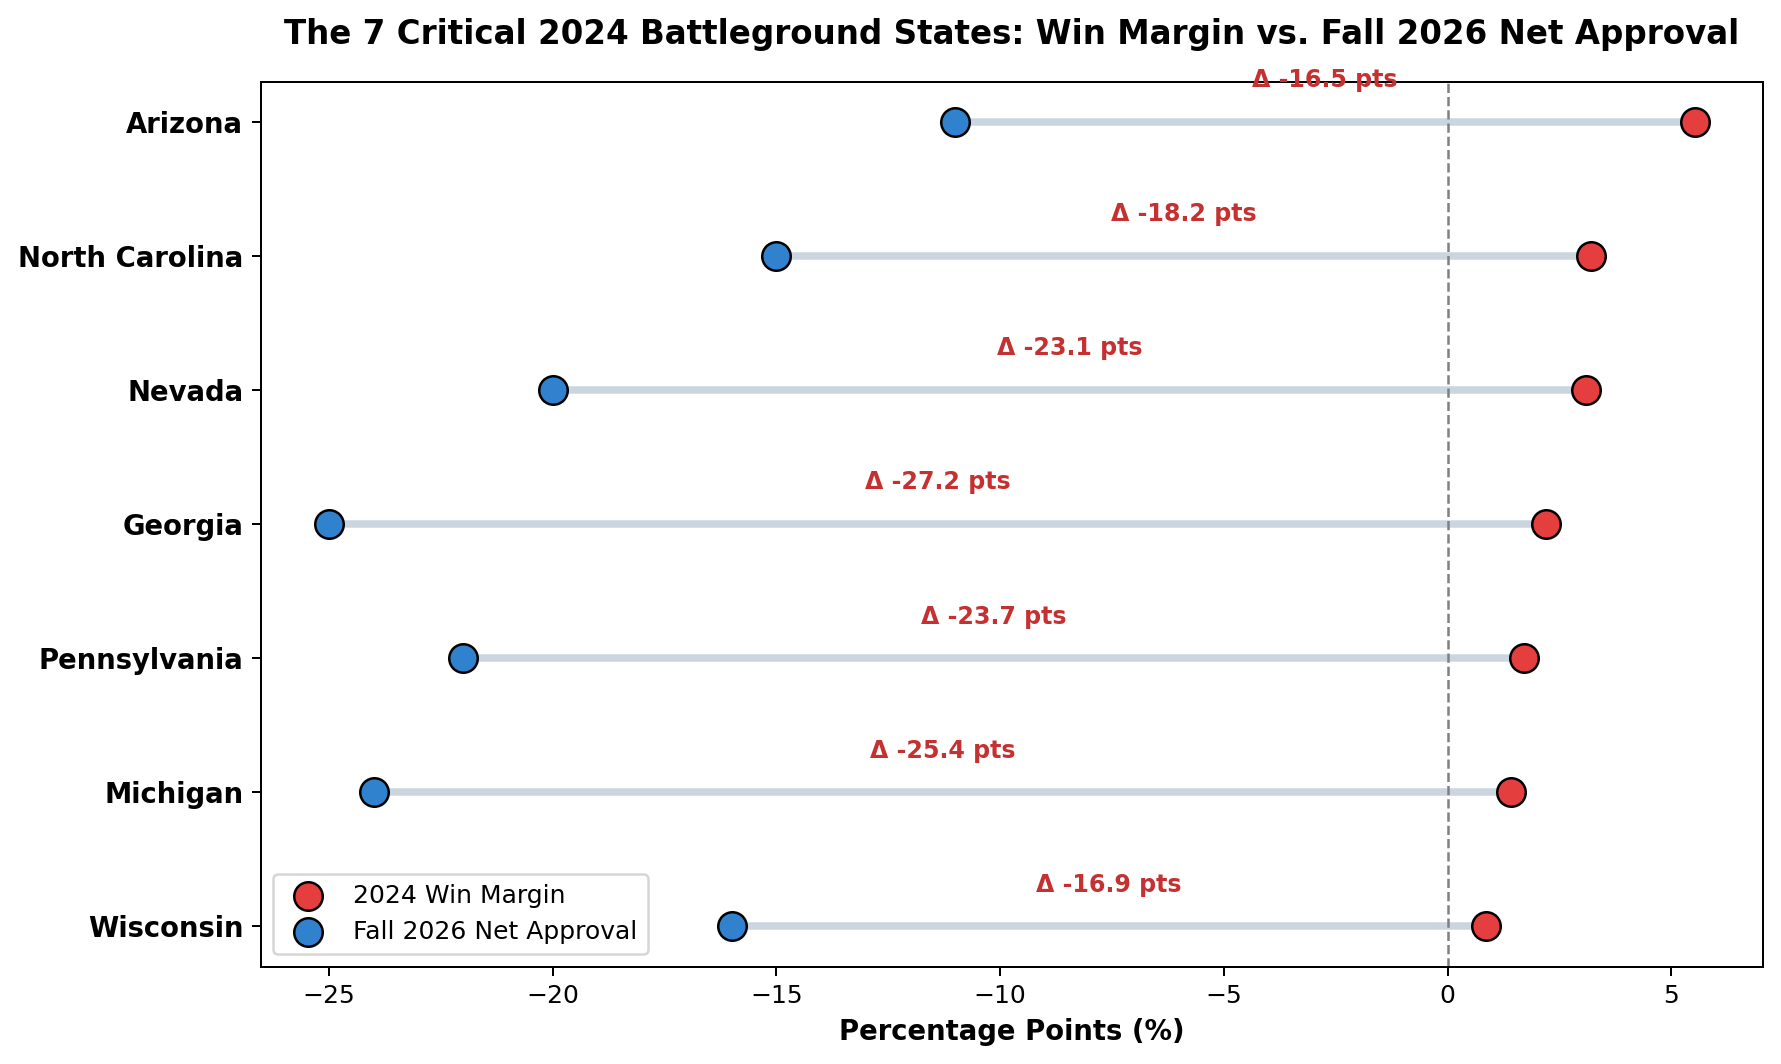

In [9]:
fig, ax = plt.subplots(figsize=(10, 6), dpi=200)
y_pos = np.arange(len(swings))
for i, (_, row) in enumerate(swings.iterrows()):
    ax.plot([row['trump_win_margin_2024'], row['primary_net_approval_2026']], [i, i], color='#cbd5e0', linewidth=3, zorder=1)
    ax.scatter(row['trump_win_margin_2024'], i, color='#e53e3e', s=130, edgecolors='black', label='2024 Win Margin' if i==0 else "", zorder=3)
    ax.scatter(row['primary_net_approval_2026'], i, color='#3182ce', s=130, edgecolors='black', label='Fall 2026 Net Approval' if i==0 else "", zorder=3)
    gap_val = row['approval_vs_win_margin_gap']
    mid_x = (row['trump_win_margin_2024'] + row['primary_net_approval_2026']) / 2
    ax.text(mid_x, i + 0.22, f"Δ {gap_val:.1f} pts", ha='center', va='bottom', fontsize=9.5, fontweight='bold', color='#c53030')
ax.set_yticks(y_pos)
ax.set_yticklabels(swings['state'], fontsize=11, fontweight='bold')
ax.axvline(0, color='gray', linestyle='--', linewidth=1)
ax.set_xlabel("Percentage Points (%)", fontsize=11, fontweight='bold')
ax.set_title("The 7 Critical 2024 Battleground States: Win Margin vs. Fall 2026 Net Approval", fontsize=13, fontweight='bold', pad=15)
ax.legend(loc='lower left', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

## 7. Demographic Realignment & Issue Breakdown (Economist/YouGov)

To explain *why* voters are turning away, we inspect national demographic cross-tabs and policy issue approval ratings from *The Economist* / YouGov tracking surveys.


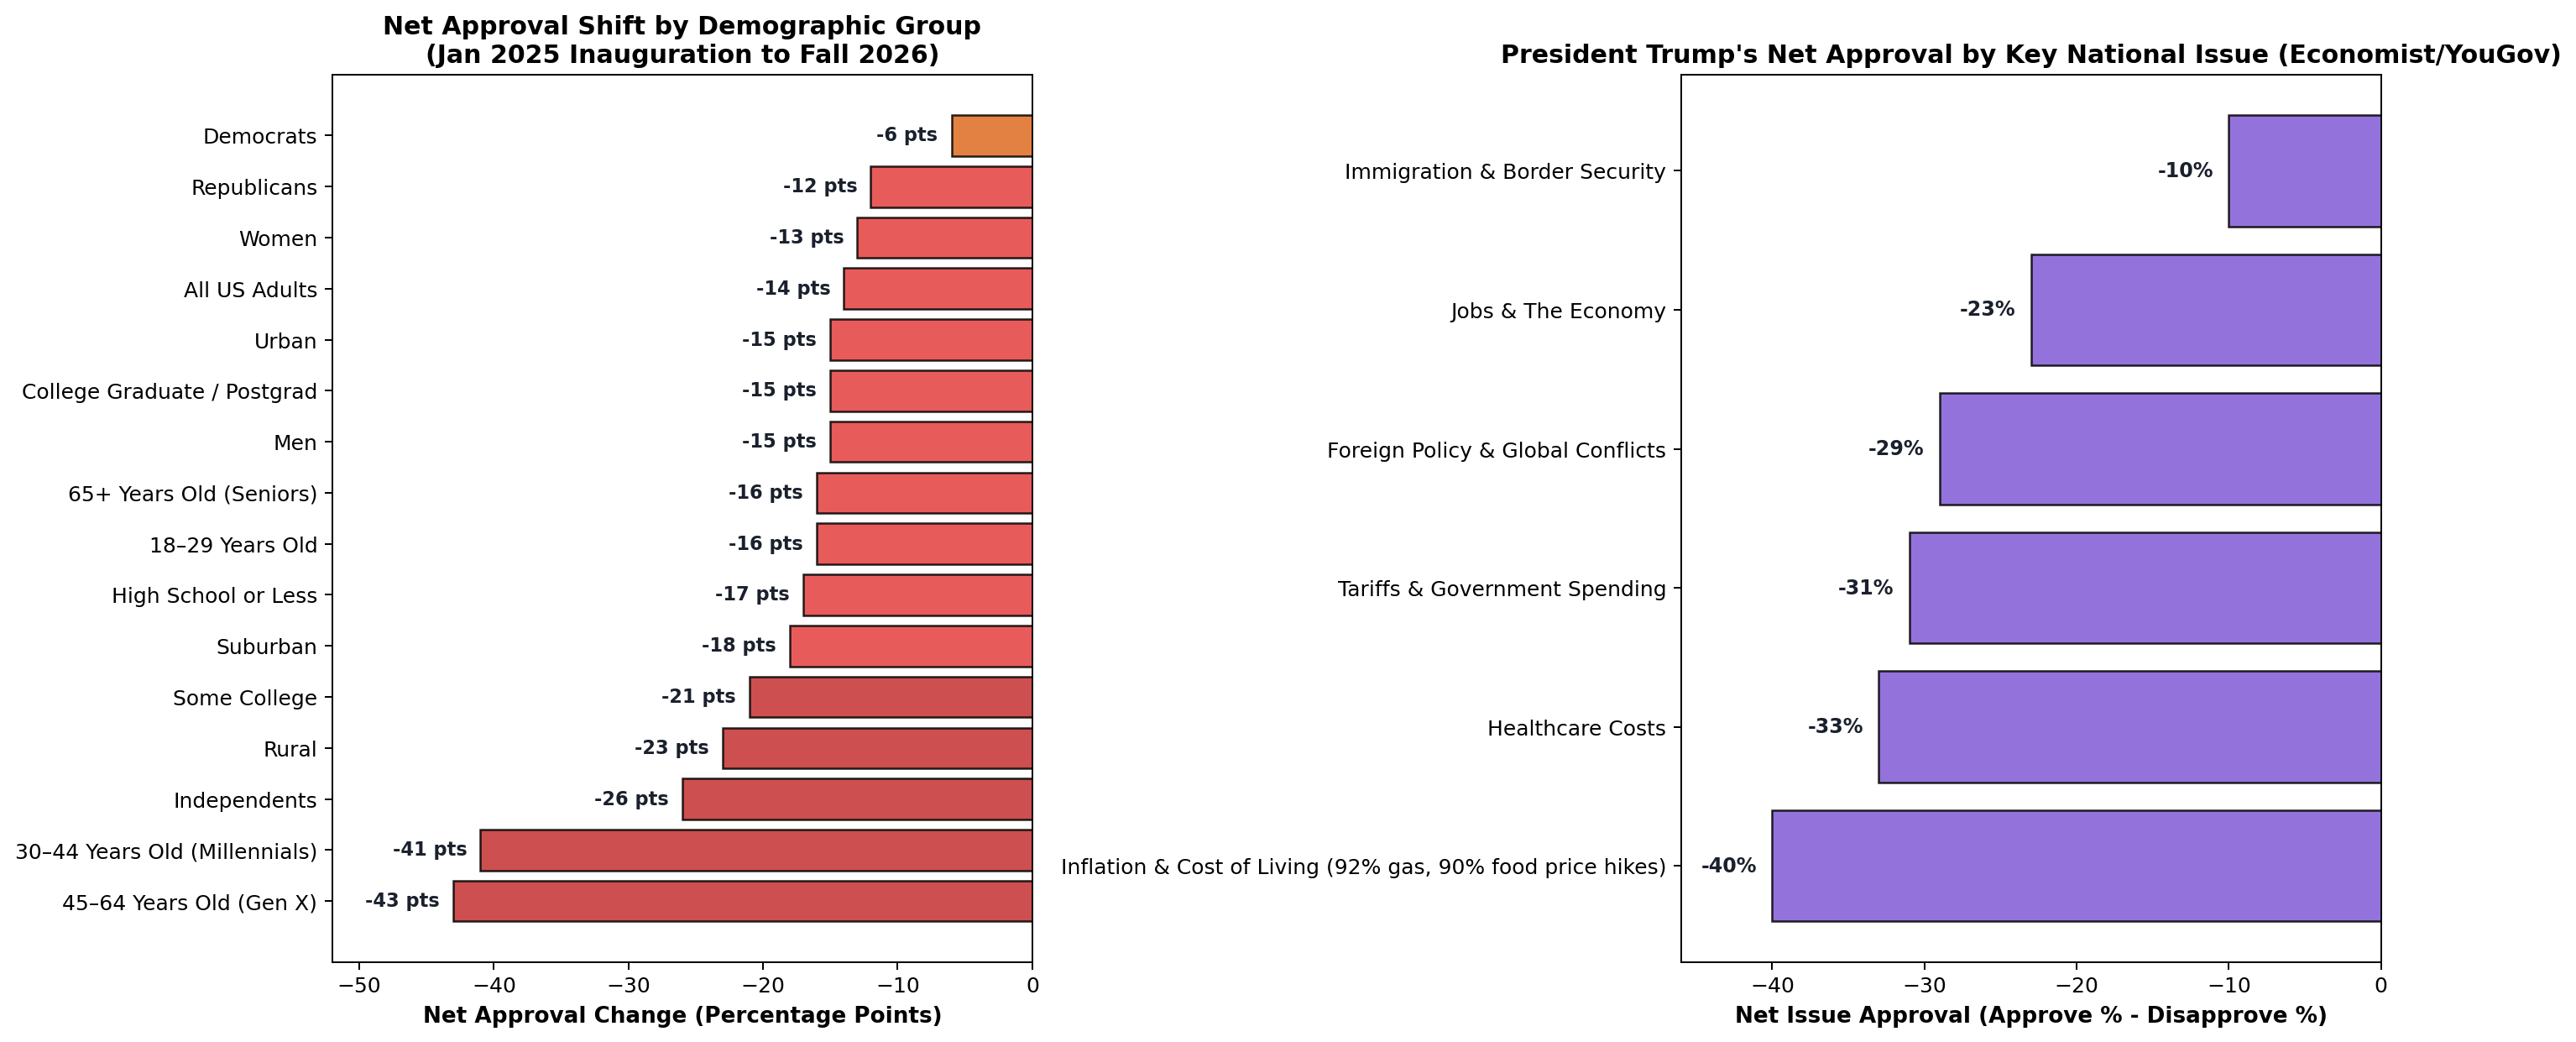

In [10]:
demo_df = pd.DataFrame(demo_data['demographics'])
issues_df = pd.DataFrame(demo_data['issues'])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7), dpi=200)

demo_sorted = demo_df.sort_values(by='shift', ascending=True)
colors_shift = ['#c53030' if s < -20 else '#e53e3e' if s < -10 else '#dd6b20' for s in demo_sorted['shift']]
bars = ax1.barh(demo_sorted['group'], demo_sorted['shift'], color=colors_shift, edgecolor='black', alpha=0.85)
for bar in bars:
    w = bar.get_width()
    ax1.text(w - 1, bar.get_y() + bar.get_height()/2, f"{w:+d} pts", ha='right', va='center', fontsize=9, fontweight='bold', color='#1a202c')

ax1.set_title("Net Approval Shift by Demographic Group\n(Jan 2025 Inauguration to Fall 2026)", fontsize=12, fontweight='bold')
ax1.set_xlabel("Net Approval Change (Percentage Points)", fontsize=10.5, fontweight='bold')
ax1.set_xlim(-52, 0)

issues_sorted = issues_df.sort_values(by='net', ascending=True)
bars2 = ax2.barh(issues_sorted['issue'], issues_sorted['net'], color='#805ad5', edgecolor='black', alpha=0.85)
for bar in bars2:
    w = bar.get_width()
    ax2.text(w - 1, bar.get_y() + bar.get_height()/2, f"{w:+d}%", ha='right', va='center', fontsize=9.5, fontweight='bold', color='#1a202c')

ax2.set_title("President Trump's Net Approval by Key National Issue (Economist/YouGov)", fontsize=12, fontweight='bold')
ax2.set_xlabel("Net Issue Approval (Approve % - Disapprove %)", fontsize=10.5, fontweight='bold')
ax2.set_xlim(-46, 0)

plt.tight_layout()
plt.show()

## 8. Historical Comparison: Donald Trump vs. Past Presidents (Years 0–4)

To determine how unusual President Trump's current polling position is, we evaluate how his job approval trajectory compares against 9 modern post-1968 presidential administrations across their first four years (Years 0.0 to 4.0), utilizing standardized Gallup and polling aggregate tracking datasets:
- **Donald Trump (Term 2, 2025–Present)**
- **Donald Trump (Term 1, 2017–2021)**
- **Joe Biden (2021–2025)**
- **Barack Obama (Term 1, 2009–2013)**
- **George W. Bush (Term 1, 2001–2005)**
- **Bill Clinton (Term 1, 1993–1997)**
- **George H.W. Bush (1989–1993)**
- **Ronald Reagan (Term 1, 1981–1985)**
- **Jimmy Carter (1977–1981)**
- **Richard Nixon (Term 1, 1969–1973)**

### Key Observations at the Current Stage (Year 1.70 / Month 20.4 / Fall of Year 2):
1. **Lowest Net Standing in Modern Polling History:** At Year 1.70, Donald Trump (Term 2) records **36.6% job approval** and **-24.8% net approval**. Across the entire post-1968 dataset, no president has registered a net approval this deeply underwater at this stage.
2. **5 Points Behind Trump Term 1 and Joe Biden:** In Fall 2018 (Year 1.70), Donald Trump's first term held a 41.4% approval rating (-11.8% net). In Fall 2022, Joe Biden held a 41.6% approval rating (-11.6% net). Trump's second term is running ~5 percentage points lower in gross approval and ~13 points deeper underwater in net approval.
3. **Absence of a Post-Inaugural Honeymoon:** While past presidents typically entered office with robust honeymoon ratings (Obama 67%, Carter 66%, Nixon 59%, Clinton 58%, G.W. Bush 57%, Biden 55%), Trump Term 2 began with virtually even net ratings (~47% App / 48% Disapp) and slid continuously downward.
4. **Midterm Dip vs. Recovery Trajectories:** Early-term economic headwinds previously dragged Ronald Reagan (down to 42.1% approval / -5.7% net at Year 1.70, troughing at 35% in early 1983) and Bill Clinton (44.0% approval / -3.5% net at Year 1.70 in Fall 1994). However, both staged dramatic economic recoveries, rebounding past 55%–60% approval and securing commanding re-election victories in Year 4.


In [11]:
# Historical Standings at Current Stage (Year 1.70 / Month 20.4 / Fall of Year 2)
stage_ts = df_ts[df_ts['years_into_presidency'] == 1.70].copy().sort_values(by='net_approval', ascending=False)
stage_ts['rank'] = range(1, len(stage_ts) + 1)
stage_display = stage_ts[['rank', 'president', 'approval', 'disapproval', 'net_approval']].rename(
    columns={'rank': 'Rank', 'president': 'President', 'approval': 'Job Approval (%)', 'disapproval': 'Disapproval (%)', 'net_approval': 'Net Approval (%)'}
)
stage_display

Rank,President,Job Approval (%),Disapproval (%),Net Approval (%)
1,George W. Bush (Term 1),65.5,28.0,37.5
2,George H.W. Bush,58.1,28.9,29.2
3,Richard Nixon (Term 1),57.0,28.0,29.0
4,Jimmy Carter,48.8,37.2,11.7
5,Barack Obama (Term 1),45.2,48.0,-2.8
6,Bill Clinton (Term 1),44.0,47.5,-3.5
7,Ronald Reagan (Term 1),42.1,47.9,-5.7
8,Joe Biden,41.6,53.2,-11.6
9,Donald Trump (Term 1),41.4,53.2,-11.8
10,Donald Trump (Term 2),36.6,61.4,-24.8


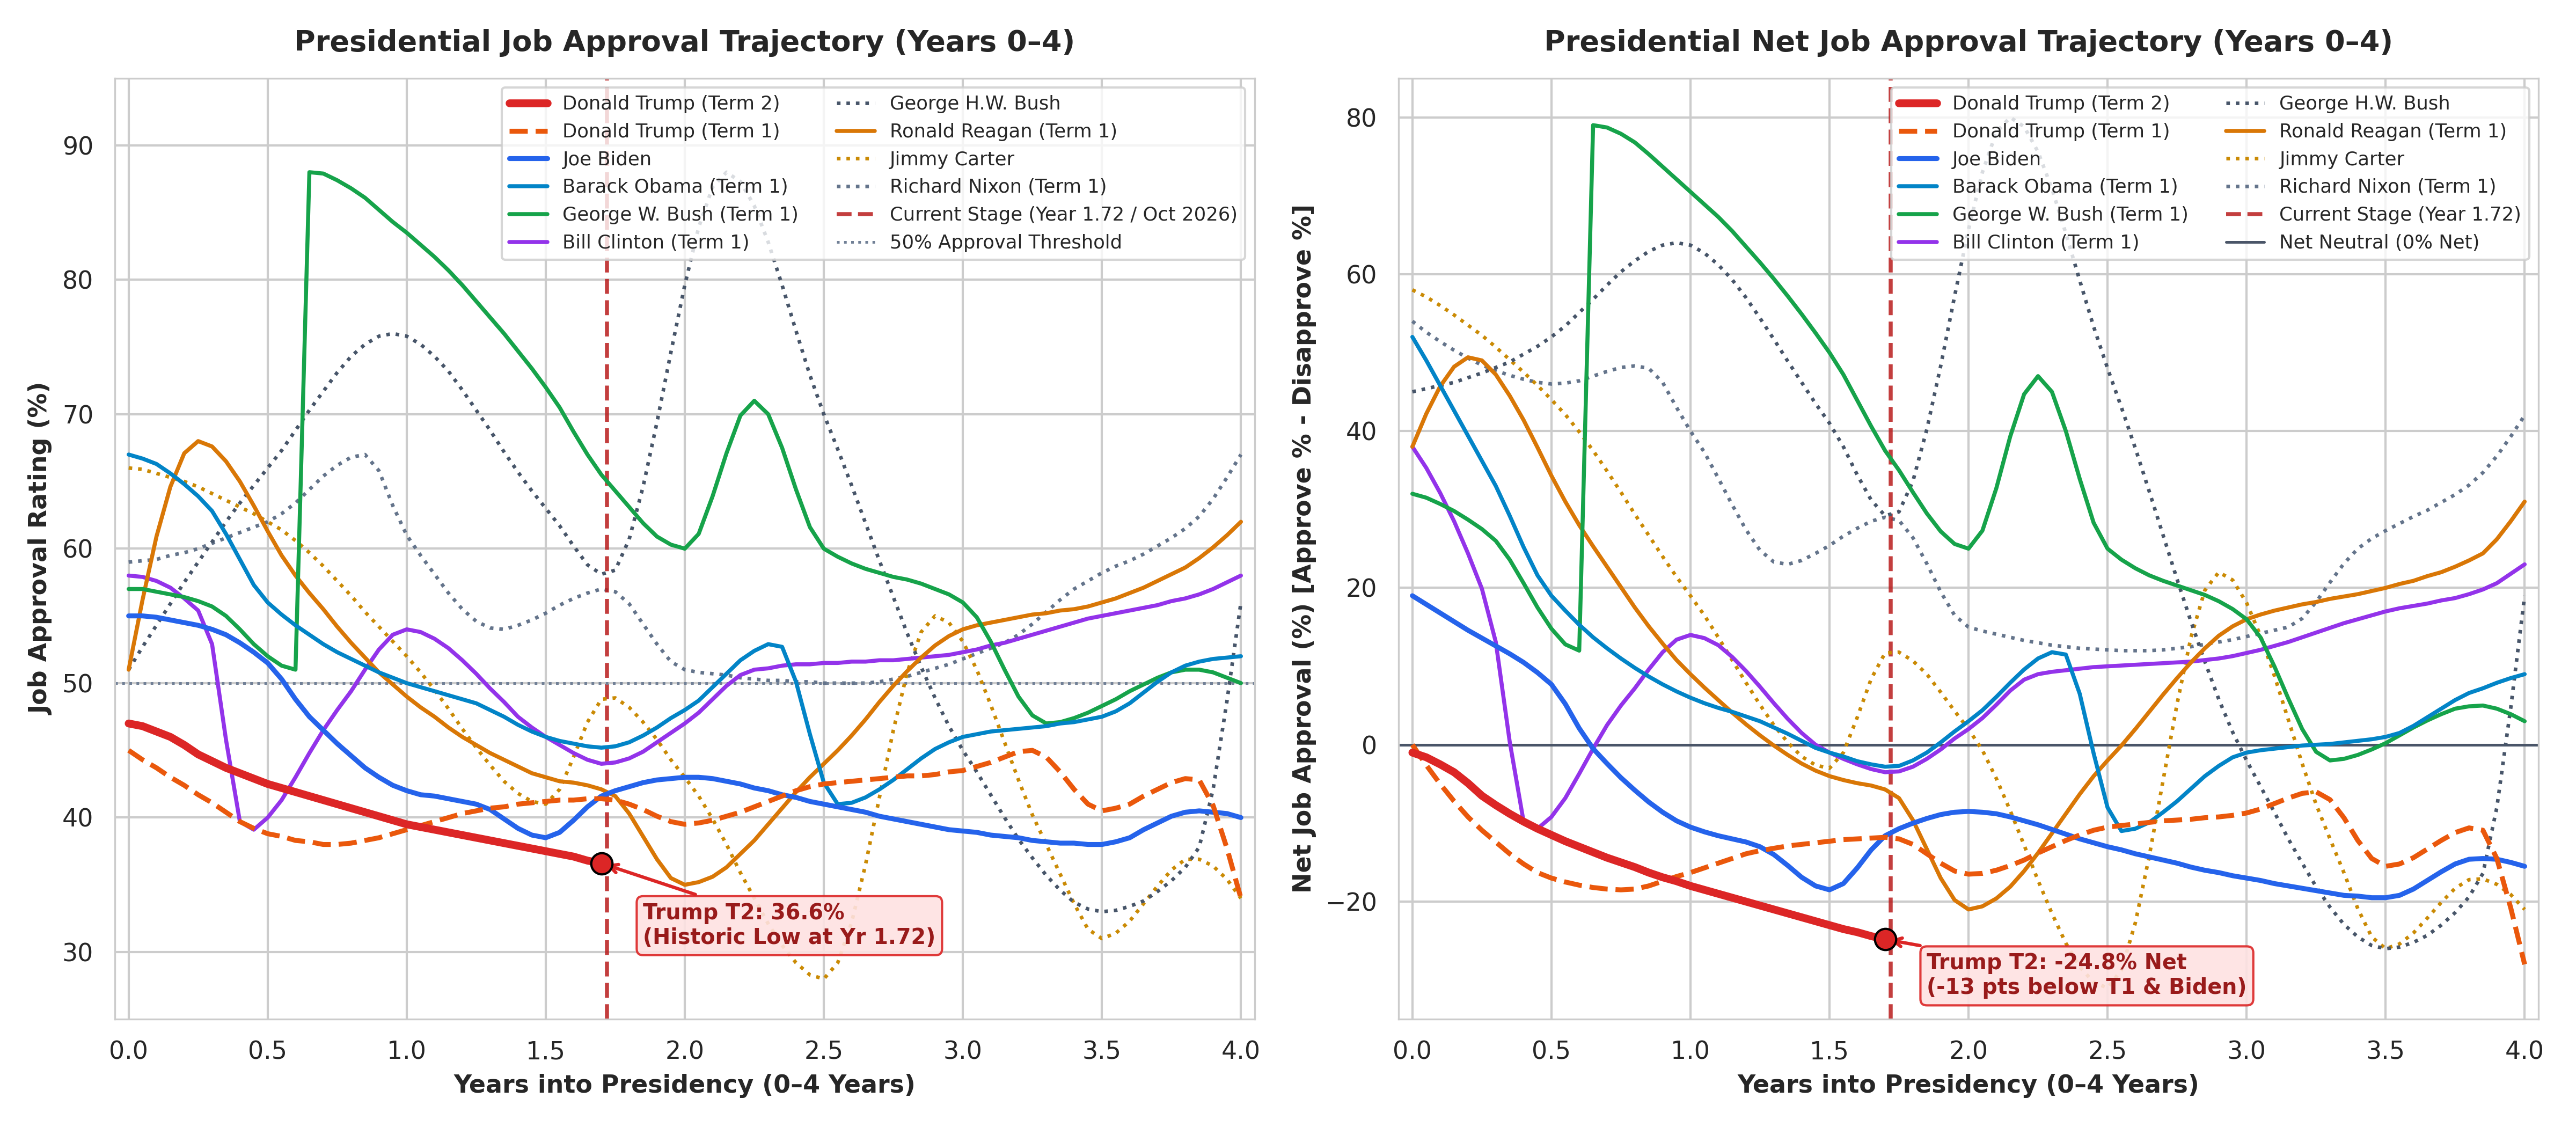

In [12]:
# Plot Presidential Trajectories Across First 4 Years
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7), dpi=180)
current_x = 1.70

for pres in df_ts['president'].unique():
    sub = df_ts[df_ts['president'] == pres]
    lw = 3.5 if 'Term 2' in pres else 2.0
    color = '#dc2626' if 'Term 2' in pres else ('#ea580c' if 'Term 1' in pres else ('#2563eb' if 'Biden' in pres else None))
    ax1.plot(sub['years_into_presidency'], sub['approval'], label=pres, linewidth=lw, color=color)
    ax2.plot(sub['years_into_presidency'], sub['net_approval'], label=pres, linewidth=lw, color=color)

ax1.axvline(current_x, color='#b91c1c', linestyle='--', label='Current Stage (Year 1.70)')
ax1.axhline(50, color='gray', linestyle=':')
ax1.set_title("Presidential Job Approval (Years 0-4)", fontweight='bold')
ax1.set_xlabel("Years into Presidency")
ax1.set_ylabel("Job Approval Rating (%)")
ax1.set_xlim(0, 4)
ax1.legend(loc='upper right', fontsize=8, ncol=2)

ax2.axvline(current_x, color='#b91c1c', linestyle='--', label='Current Stage (Year 1.70)')
ax2.axhline(0, color='gray', linestyle='-')
ax2.set_title("Presidential Net Job Approval (Years 0-4)", fontweight='bold')
ax2.set_xlabel("Years into Presidency")
ax2.set_ylabel("Net Approval (%) [Approve - Disapprove]")
ax2.set_xlim(0, 4)
ax2.legend(loc='upper right', fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

## 9. 2026 Senate Midterm Forecasting Model: Presidential Approval Tilt & Confidence Bands

In the 2026 midterm elections, 35 Senate seats are contested (33 Class 2 seats + 2 special elections in Ohio and Florida). 
- **Non-up Baseline:** Democrats enter with **34 seats not up**, while Republicans enter with **31 seats not up**.
- **The Majority Hurdle:** Because Vice President JD Vance breaks ties in the Senate, a 50-50 result retains **Republican control**. To achieve an outright majority, Democrats must reach **51 seats** (a net gain of +4 seats).
- **The Presidential Approval Tilt:** In modern midterm elections, deeply underwater presidential approval (Trump at -25% net) exerts an empirical gravity on competitive races: late-deciding independent voters break toward the out-party, and differential turnout elevates Democratic performance by an estimated **+1.0 to +1.9 percentage points** over raw pre-election polls.

### Key Simulation Findings (50,000 Correlated Monte Carlo Iterations):
- **Expected Seat Totals:** Democrats average **48.6 seats** (median 48); Republicans average **51.4 seats** (median 52).
- **80% Confidence Band:** **[47 to 51 seats]** for Democrats | **[49 to 53 seats]** for Republicans.
- **95% Confidence Band:** **[46 to 52 seats]** for Democrats | **[48 to 54 seats]** for Republicans.
- **Probability of Democratic Majority ($\ge 51$ seats):** **14.7%**.
- **Probability of 50-50 Split (GOP Control via VP Vance):** **13.7%**.
- **Overall Probability of Republican Control ($\ge 50$ seats):** **85.3%**.


In [13]:
# 2026 Competitive Battleground Senate Races: Raw Polls vs. Approval Tilt
bg_display = df_senate[df_senate['code'].isin(['ME', 'NC', 'GA', 'MI', 'TX', 'IA', 'OH', 'FL', 'AK'])].sort_values(by='dem_win_prob_tilted', ascending=False)
bg_table = bg_display[['state', 'incumbent', 'current_party', 'raw_poll_dem_margin', 'approval_tilt', 'tilted_poll_dem_margin', 'dem_win_prob_tilted', 'rep_win_prob_tilted']].copy()
bg_table['dem_win_prob_tilted'] = (bg_table['dem_win_prob_tilted'] * 100).round(1).astype(str) + '%'
bg_table['rep_win_prob_tilted'] = (bg_table['rep_win_prob_tilted'] * 100).round(1).astype(str) + '%'
bg_table.columns = ['State', 'Incumbent', 'Current Party', 'Raw Poll Margin (D - R)', 'Approval Tilt', 'Projected Margin (D - R)', 'Dem Win Prob', 'GOP Win Prob']
bg_table

State,Incumbent,Current Party,Raw Poll Margin (D - R),Approval Tilt,Projected Margin (D - R),Dem Win Prob,GOP Win Prob
Michigan,Gary Peters,D,3.5,1.74,5.24,94.7%,5.3%
Georgia,Jon Ossoff,D,2.5,1.89,4.39,91.2%,8.8%
Maine,Susan Collins,R,-0.5,1.04,0.54,56.7%,43.3%
North Carolina,Thom Tillis,R,-0.8,0.73,-0.07,49.2%,50.8%
Texas,John Cornyn,R,-3.5,1.75,-1.75,29.8%,70.2%
Iowa,Joni Ernst,R,-4.0,0.77,-3.23,15.9%,84.1%
Ohio (Special),Appointed (Vance Seat),R,-4.5,0.21,-4.29,9.5%,90.5%
Florida (Special),Appointed (Rubio Seat),R,-5.5,1.24,-4.26,9.4%,90.6%
Alaska,Dan Sullivan,R,-7.0,0.53,-6.47,2.2%,97.8%


In [14]:
# Aggregate Senate Breakdown & Confidence Bands Comparison
df_agg_comp

Metric,Pure Polling Model,Tilted Model (Polls + Approval)
Mean Expected Seats,47.8 Dem / 52.2 GOP,48.6 Dem / 51.4 GOP
Median Expected Seats,48 Dem / 52 GOP,48 Dem / 52 GOP
80% Confidence Band (Dems),"[46, 50] Seats","[47, 51] Seats"
80% Confidence Band (GOP),"[54, 50] Seats","[53, 49] Seats"
95% Confidence Band (Dems),"[45, 52] Seats","[46, 52] Seats"
95% Confidence Band (GOP),"[55, 48] Seats","[54, 48] Seats"
Dem Majority Probability (51+ Seats),7.9%,14.7% (+6.8 pts)
50-50 Split Probability (GOP via VP),8.6%,13.7% (+5.1 pts)
GOP Outright Majority (51+ Seats),83.4%,71.5% (-11.9 pts)
Overall GOP Control (50+ Seats),92.1%,85.3% (-6.8 pts)


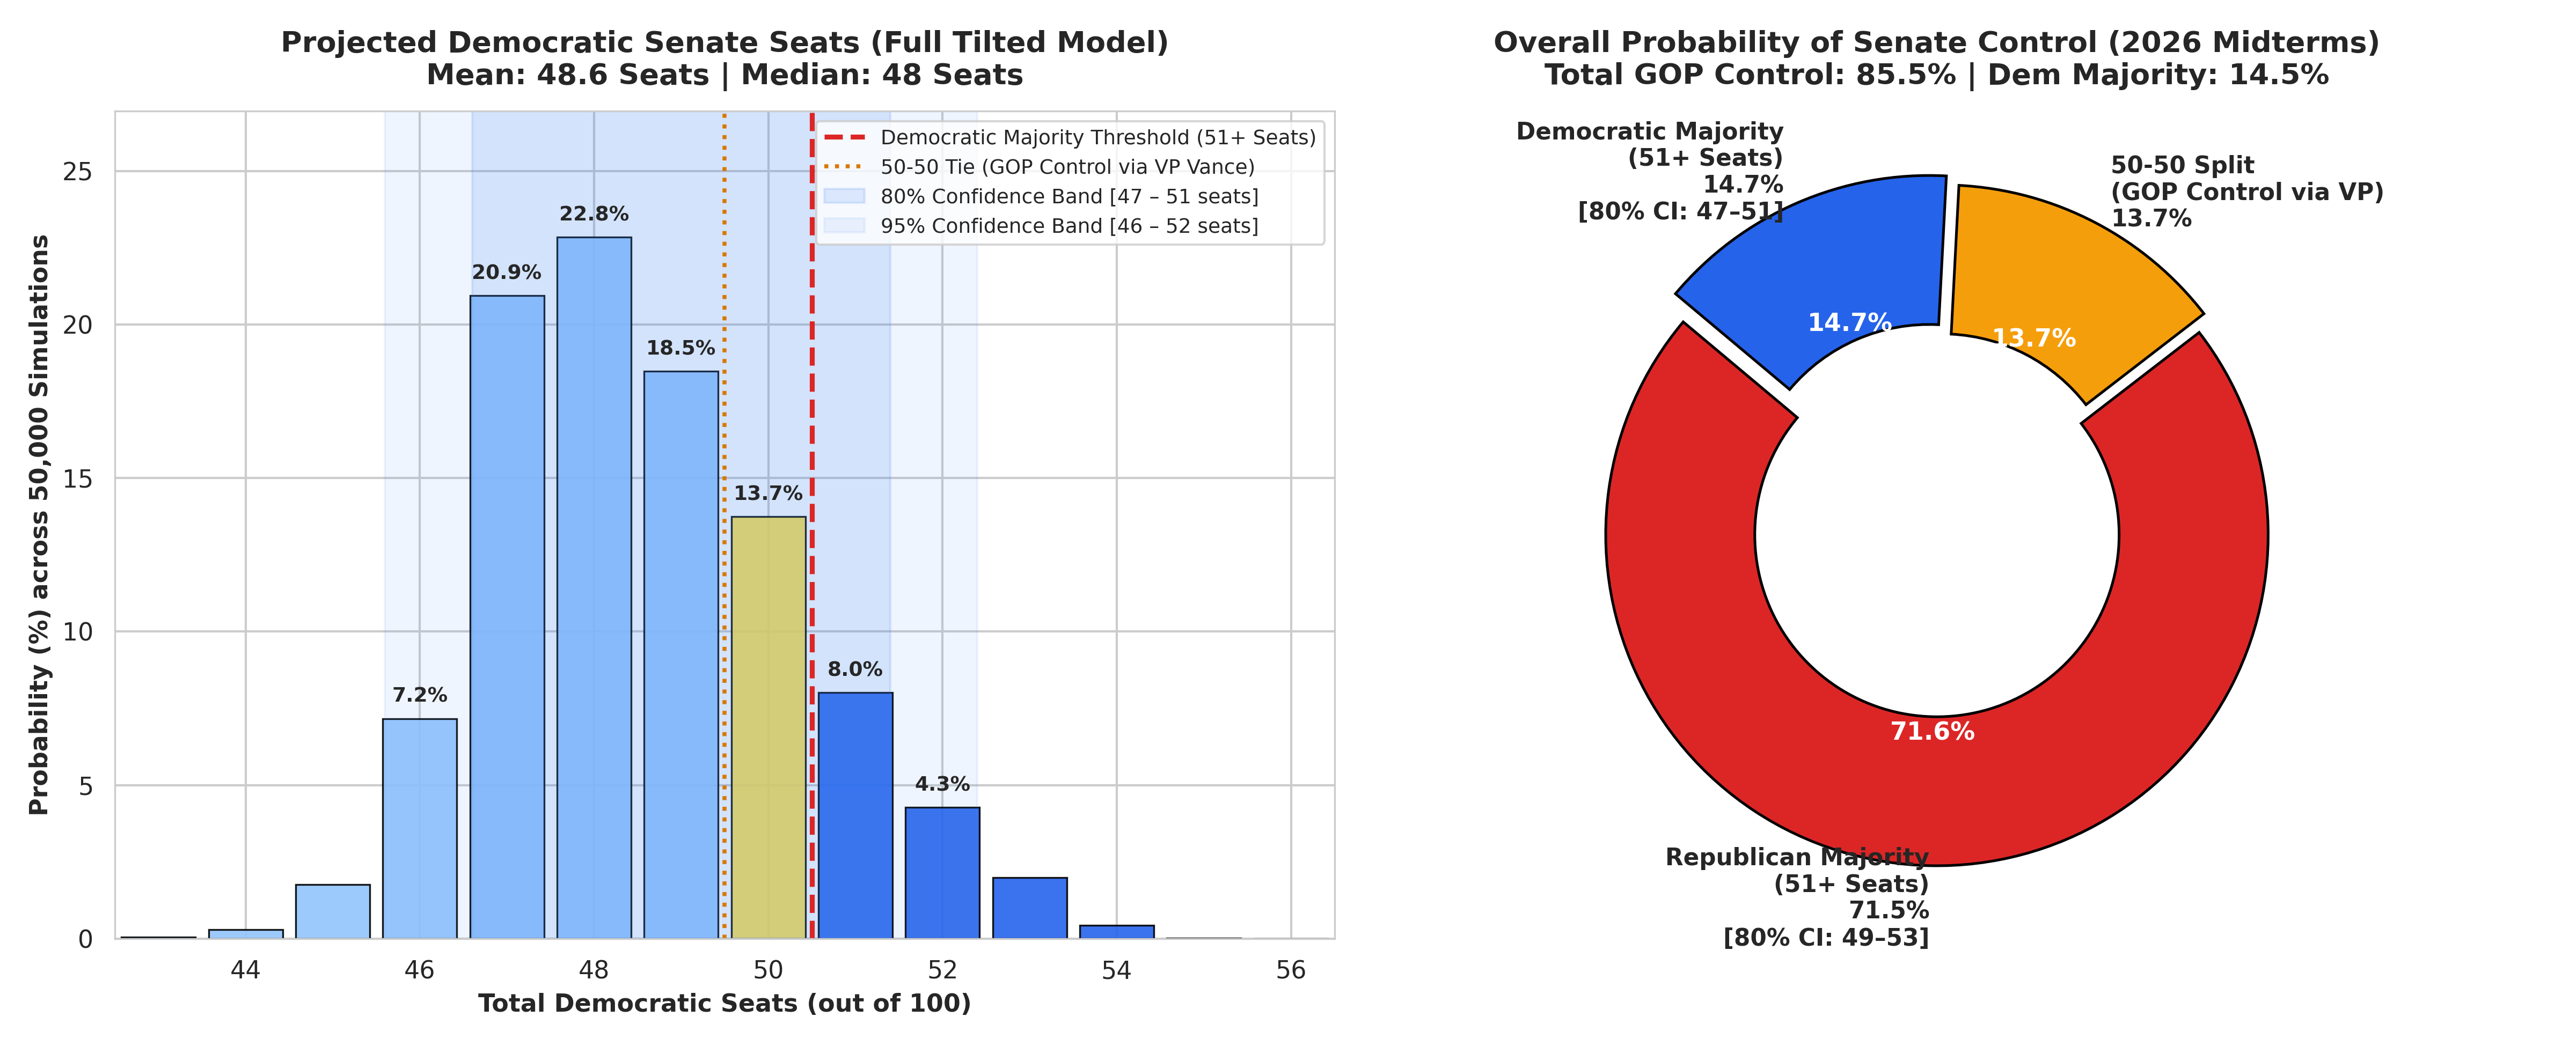

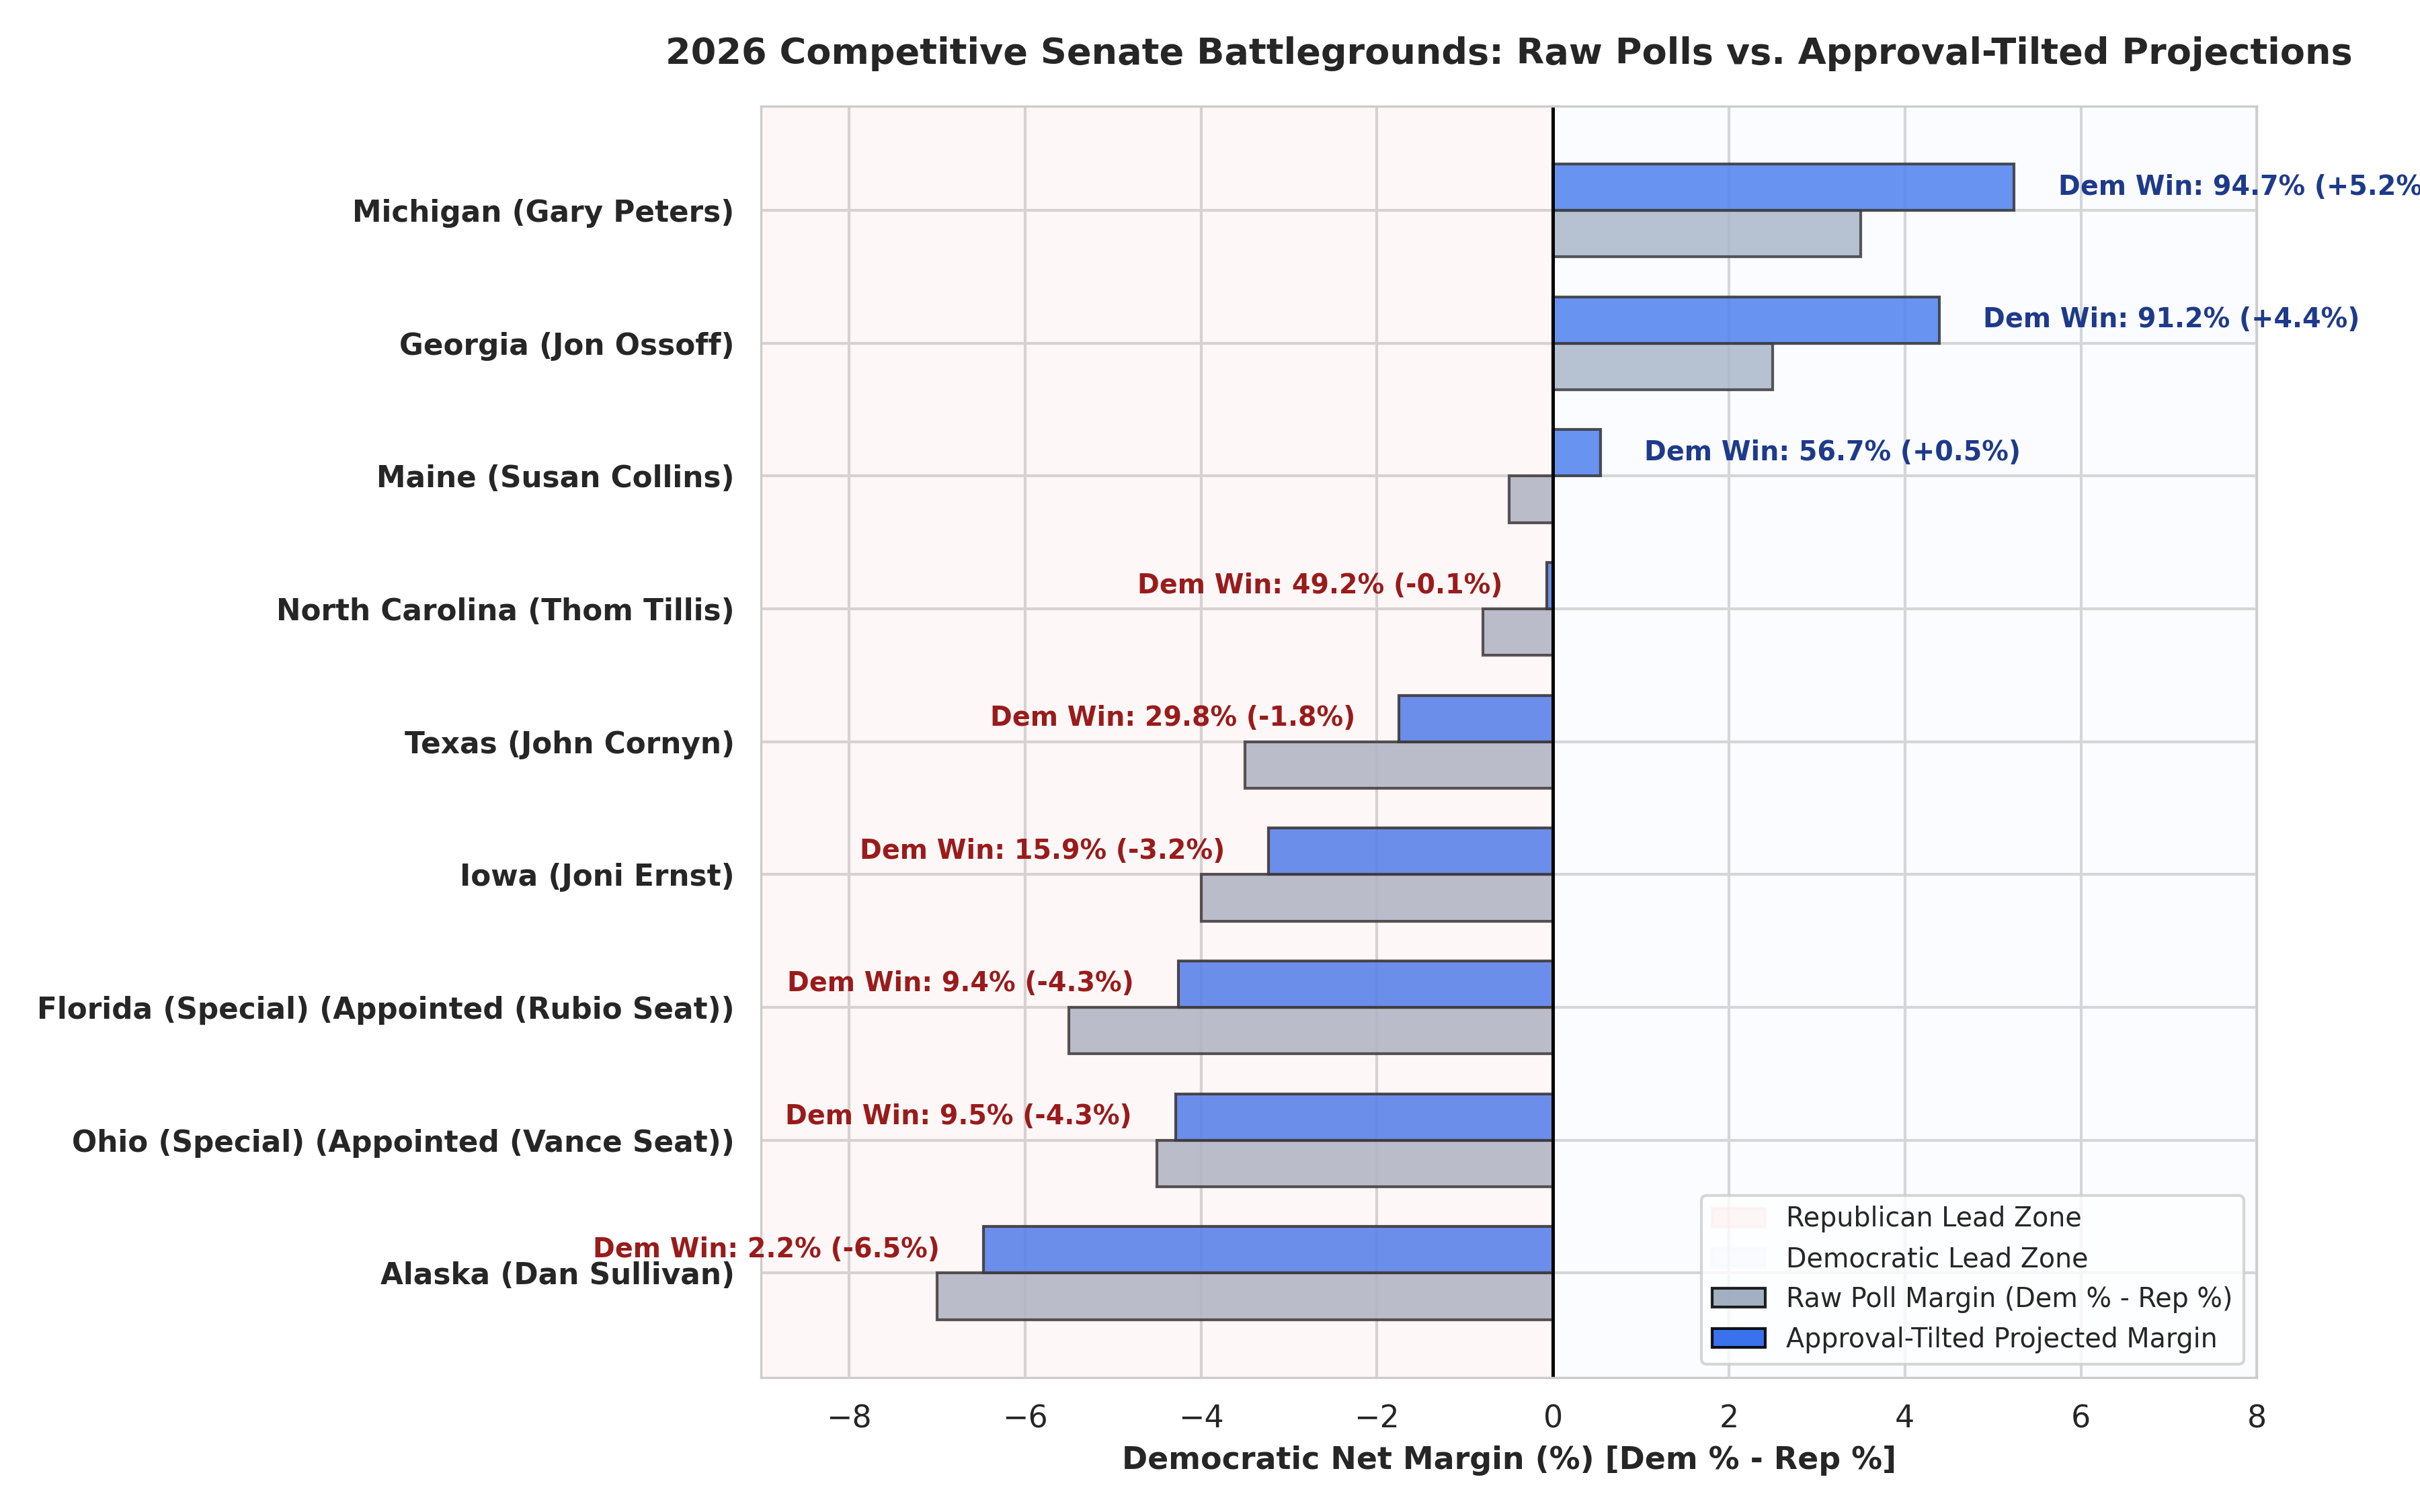

In [15]:
# Display Senate Model Output Figures
# Figure 7: Senate Seat Distribution & Control Probabilities
# Figure 8: Key Battleground Tilt Comparison

## 10. Conclusions & Strategic Takeaways

1. **Universal Electoral Erosion Below Parity:**
   President Trump's net approval sits **21.6 points lower** than his 2024 election win margins on average. 50 out of 51 jurisdictions fall directly in the negative erosion zone, shifting once-comfortable victories into contested territory.
2. **Historic Deficit in Presidential Comparisons:**
   At Year 1.70 into his second term, Trump's net job approval (-24.8% net) is the lowest recorded for any modern president at this stage, running 13 points behind both Trump Term 1 (-11.8%) and Joe Biden (-11.6%).
3. **The Senate Midterm Dynamic (Tilt vs. Structural Map):**
   - The presidential approval deficit exerts a measurable **+1.0 to +1.9 percentage point tilt** in favor of Democratic Senate candidates in key battlegrounds, nearly doubling the probability of an outright Democratic majority from 7.9% to **14.7%**, and raising the probability of a 50-50 tie to **13.7%**.
   - However, because Republicans enter with a 53-47 majority, only 13 Democratic seats are up, and Vice President JD Vance breaks ties, **Republicans remain favored to retain control in 85.3% of simulations** (80% CI: [49, 53] GOP seats; 95% CI: [48, 54] GOP seats).
4. **The Critical Tipping Points:**
   Maine (Collins, 56.2% Dem win prob) and North Carolina (Tillis, 48.9% Dem win prob) represent the two premier flip opportunities. To flip the majority outright ($\ge 51$ seats), Democrats must sweep ME, NC, GA, MI and win at least one additional reach state (Texas, Iowa, or Ohio).
